# The Hedge Desk
## One client. One option. Seven decisions.

You sold a three-month call. You can trade the stock and cash, but not volatility.
First read the market: calibrate a model to option quotes. Then build a hedge and the
evidence that it works: a formula, a backward regression, a trained network, a band for
trading costs. Finally, stress the hedges, find where they lose, and recommend one.

**Read assignment.pdf alongside this notebook.** Complete the thirteen **Task** functions
and the written questions. Your functions drive the experiments. The simulator,
Fourier pricer, quote tools, network architecture and checkpoint selection are provided.

**Setup:** Python 3.9+, NumPy, SciPy, Matplotlib and PyTorch; CPU is sufficient.
Keep market_data.npz next to this notebook. Locally use "pip install -r requirements.txt"
and open this notebook in Jupyter. In Colab, upload this notebook and market_data.npz.
If an import is missing, run "%pip install numpy scipy matplotlib torch" in a new cell.

Set QUICK=True while developing. For the report use QUICK=False, which retains
three training seeds. Choose the configuration **before** viewing test results.
The test paths are in the data file: this is a reproducibility exercise, not a securely
hidden leaderboard. A failed assertion is a debugging prompt; outperforming a benchmark
is not required.

**Notation:** array column k is the holding chosen at date $t_k$ for
$(t_k,t_{k+1}]$: it is $\phi_{k+1}$ in the notes. Rates are zero. All paths are
under the pricing measure $\mathbb Q$: your calibrated model for training, the market
itself for the test. The raw Euler variance is observed in this assignment.

In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/hedge-desk-matplotlib")
import copy
import itertools
import json
import time
import hashlib
import platform
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.special import ndtr

"""Provided market simulator, pricer, quote tools and network architecture.
Student accounting, calibration, regression, training and trading rules live in
hedge_desk.ipynb and are used throughout.
"""
from dataclasses import dataclass, asdict
import math
import numpy as np
import torch
from torch import nn


@dataclass(frozen=True)
class Heston:
    spot: float = 100.0
    strike: float = 100.0
    expiry: float = 0.25
    steps: int = 63
    kappa: float = 2.0
    theta: float = 0.04
    xi: float = 0.5
    rho: float = -0.7
    v0: float = 0.04

def simulate(n, seed, model=Heston()):
    """Return path-major (S, raw v), each with shape (n, steps+1)."""
    rng = np.random.default_rng(seed)
    dt = model.expiry / model.steps
    s = np.empty((model.steps + 1, n)); v = np.empty_like(s)
    s[0], v[0] = model.spot, model.v0
    for k in range(model.steps):
        z1 = rng.standard_normal(n)
        z2 = model.rho * z1 + math.sqrt(1-model.rho**2) * rng.standard_normal(n)
        vp = np.maximum(v[k], 0.)
        s[k+1] = s[k] * np.exp(-.5*vp*dt + np.sqrt(vp*dt)*z1)
        v[k+1] = v[k] + model.kappa*(model.theta-vp)*dt + model.xi*np.sqrt(vp*dt)*z2
    return s.T.copy(), v.T.copy()

def tensors(s, v, model=Heston(), device='cpu'):
    """Features at the decision date; terminal prices appear only in targets/gains."""
    tau = model.expiry * np.arange(model.steps, 0, -1) / model.steps
    x = np.stack([np.broadcast_to(tau/model.expiry, s[:, :-1].shape),
                  np.log(s[:, :-1]/model.strike)/np.sqrt(model.theta*tau),
                  v[:, :-1]/model.theta-1.], axis=-1)
    return {k: torch.as_tensor(a, dtype=torch.float32, device=device) for k,a in
            dict(features=x, spot=s, increments=np.diff(s,axis=1),
                 payoff=np.maximum(s[:, -1]-model.strike, 0.)).items()}

class HedgeNet(nn.Module):
    """Shared date-conditioned 2x32 tanh network, with optional recurrent inputs.

    The default family uses time, spot and raw variance; previous holding is an
    optional input. This restricted family is not claimed to contain the CVaR
    optimum. include_gain adds cumulative net trading gains as a state feature.
    """
    def __init__(self, holding=False, include_gain=False, width=32):
        super().__init__()
        self.holding, self.include_gain, self.width = holding, include_gain, width
        self.layers = nn.Sequential(nn.Linear(3+int(holding)+int(include_gain), width),
                                    nn.Tanh(), nn.Linear(width,width), nn.Tanh(), nn.Linear(width,1))
        nn.init.normal_(self.layers[-1].weight, std=.01)
        nn.init.constant_(self.layers[-1].bias, .5)

    def forward(self, x):
        return self.layers(x).squeeze(-1)

    def config(self):
        return dict(holding=self.holding, include_gain=self.include_gain, width=self.width)

def warm_start(source, holding=False, include_gain=False):
    """Copy a fitted market-state policy; added recurrent input weights start at zero."""
    net=HedgeNet(holding, include_gain, source.width)
    with torch.no_grad():
        net.layers[0].weight.zero_()
        net.layers[0].weight[:, :3].copy_(source.layers[0].weight[:, :3])
        net.layers[0].bias.copy_(source.layers[0].bias)
        for i in [2,4]:
            net.layers[i].load_state_dict(source.layers[i].state_dict())
    return net

def cvar_numpy(loss, tail=.05):
    """Empirical CVaR with fractional boundary mass; last axis is paths."""
    loss=np.asarray(loss, dtype=float)
    n=loss.shape[-1]; m=tail*n; k=int(np.floor(m+1e-12)); frac=m-k
    ordered=np.partition(loss, n-k-1, axis=-1)
    total=ordered[...,-k:].sum(axis=-1) if k else np.zeros(loss.shape[:-1])
    if frac>1e-10: total=total+frac*ordered[...,n-k-1]
    return total/m

def heston_greeks(S, v, tau, rho=None, L=12.0, model=Heston()):
    """Price, C_S and C_v of the call for arrays of spot S and variance v, at time to expiry tau.

    Cosine expansion of Heston's characteristic function on an interval of half-width h
    around each log-moneyness; more terms are used in the last week, where densities are narrow."""
    rho = model.rho if rho is None else rho
    S, v = np.atleast_1d(S).astype(float), np.atleast_1d(v).astype(float)
    N = 2048 if tau < 6 / 252 else 512
    x = np.log(S / model.strike)
    h = L * np.sqrt((3 * model.theta + max(np.quantile(v, 0.99), model.theta)) * tau)
    a, b = x - h, x + h
    # A(tau, u) and B(tau, u): Heston's closed-form characteristic-function coefficients
    k = np.arange(N); u = np.where(k == 0, 1e-12, k * np.pi / (2 * h)); iu = 1j * u
    d = np.sqrt((rho * model.xi * iu - model.kappa)**2 + model.xi**2 * (iu + u**2))
    g = (model.kappa - rho * model.xi * iu - d) / (model.kappa - rho * model.xi * iu + d); e = np.exp(-d * tau)
    B = (model.kappa - rho * model.xi * iu - d) / model.xi**2 * (1 - e) / (1 - g * e)
    A = model.kappa * model.theta / model.xi**2 * ((model.kappa - rho * model.xi * iu - d) * tau - 2 * np.log((1 - g * e) / (1 - g)))
    # cosine coefficients of the call payoff on [a, b]
    U = (k * np.pi / (2 * h))[None, :]
    c = np.clip(0.0, a, b)[:, None]; aa, bb = a[:, None], b[:, None]
    chi = (np.cos(U * (bb - aa)) * np.exp(bb) - np.cos(U * (c - aa)) * np.exp(c)
           + U * np.sin(U * (bb - aa)) * np.exp(bb) - U * np.sin(U * (c - aa)) * np.exp(c)) / (1 + U**2)
    psi = np.where(U == 0, bb - c, (np.sin(U * (bb - aa)) - np.sin(U * (c - aa))) / np.where(U == 0, 1, U))
    w = np.ones(N); w[0] = 0.5
    core = w * (2 / (2 * h)) * (chi - psi) * (b > 0)[:, None] * model.strike
    phase = np.exp(A[None, :] + B[None, :] * v[:, None] + 1j * U * (x - a)[:, None])
    price_ = np.real(phase * core).sum(1)                    # C
    C_S = np.real(1j * U * phase * core).sum(1) / S          # dC/dS: differentiate in log-moneyness
    C_v = np.real(B[None, :] * phase * core).sum(1)          # dC/dv: the integrand times B
    return price_, C_S, C_v

def quote_prices(model, strikes, tau, spot=100.0, v0=None):
    """Call prices for several strikes at one maturity; Heston prices scale with the strike."""
    strikes = np.asarray(strikes, dtype=float)
    v0 = model.v0 if v0 is None else v0
    unit = Heston(**{**asdict(model), 'strike': 100.0})
    price = heston_greeks(100.0*spot/strikes, np.full(len(strikes), v0), tau, model=unit)[0]
    return strikes/100.0*price

def bs_call(spot, strike, tau, vol):
    """Black-Scholes call price at zero rates."""
    from scipy.special import ndtr
    d1 = (np.log(spot/strike) + 0.5*vol*vol*tau)/(vol*np.sqrt(tau))
    return spot*ndtr(d1) - strike*ndtr(d1 - vol*np.sqrt(tau))

def implied_vol(price, spot, strike, tau, lo=1e-4, hi=3.0, iterations=80):
    """Vectorised bisection for Black-Scholes implied volatility (prices inside no-arbitrage bounds)."""
    price, strike = np.broadcast_arrays(np.asarray(price, float), np.asarray(strike, float))
    a, b = np.full(price.shape, lo), np.full(price.shape, hi)
    for _ in range(iterations):
        mid = 0.5*(a + b); high = bs_call(spot, strike, tau, mid) > price
        b = np.where(high, mid, b); a = np.where(high, a, mid)
    return 0.5*(a + b)


torch.set_num_threads(2)
QUICK = os.environ.get("HEDGE_DESK_QUICK", "0") == "1"
CFG = dict(
    train=3000 if QUICK else 8000, validation=1000 if QUICK else 2000,
    test=2000 if QUICK else 4000, seeds=[11] if QUICK else [11, 22, 33],
    mse_steps=180 if QUICK else 400, tail_steps=220 if QUICK else 500,
    cost_steps=180 if QUICK else 400, batch=500 if QUICK else 1000,
    validation_seed=12091, bootstrap=300 if QUICK else 600,
    rate=0.005, tail=0.05, learning_rate=0.002,
    band_grid=[0.0, 0.04, 0.08, 0.12, 0.20, 0.30],
    stress=1000 if QUICK else 4000, stress_seed=60606,
)
DATA = Path("market_data.npz")
if not DATA.exists():
    raise FileNotFoundError("Put market_data.npz next to this notebook (in Colab, upload it to the session files).")
MARKET = np.load(DATA)
SPOT, V0 = float(MARKET["spot"]), float(MARKET["variance"])
SHEET = dict(strikes=MARKET["strikes"], maturities=MARKET["maturities"], vols=MARKET["implied_vols"])
# The client pays the market's price: the quoted three-month at-the-money call.
ATM = (int(np.argmin(abs(SHEET["maturities"]-0.25))), int(np.argmin(abs(SHEET["strikes"]-100.0))))
PREMIUM = float(bs_call(SPOT, 100.0, 0.25, SHEET["vols"][ATM]))
OUT = Path("hedge_desk_output")
OUT.mkdir(exist_ok=True)
print(f"Premium (quoted): {PREMIUM:.6f}; mode: {'quick' if QUICK else 'course'}")
print(CFG)

Premium (quoted): 3.613181; mode: course
{'train': 8000, 'validation': 2000, 'test': 4000, 'seeds': [11, 22, 33], 'mse_steps': 400, 'tail_steps': 500, 'cost_steps': 400, 'batch': 1000, 'validation_seed': 12091, 'bootstrap': 600, 'rate': 0.005, 'tail': 0.05, 'learning_rate': 0.002, 'band_grid': [0.0, 0.04, 0.08, 0.12, 0.2, 0.3], 'stress': 4000, 'stress_seed': 60606}


## Brief 0 — Read the market

The market's parameters are not given. You see what a desk sees: today's stock price,
today's variance and a sheet of call quotes, as mid implied volatilities for nine strikes
and four maturities. The bid-ask half-spread is about 0.3 vol points.

**Task M1.** Calibrate $(\kappa,\bar v,\xi,\rho)$ by least squares in implied volatility,
$$\min\sum_{i,j}\bigl(\sigma^{\mathrm{model}}_{ij}-\sigma^{\mathrm{quote}}_{ij}\bigr)^2 .$$
Price each maturity's strikes with `quote_prices`, convert with `implied_vol`, and minimise
with `least_squares` inside `bounds`, once from each starting point. Keep the best fit.
Return a dict with keys kappa, theta, xi, rho, and the root-mean-square error in vol points.
The current variance is observed: keep it fixed.

The fitted model becomes the **desk's model**. Every later formula, simulation, regression
and network uses it. The test paths at the end come from the market itself.

In [2]:
from dataclasses import replace
from scipy.optimize import least_squares
BOUNDS = ([0.1, 0.005, 0.05, -0.99], [10.0, 0.2, 1.5, 0.5])
STARTS = [[1.0, 0.03, 0.3, -0.3], [3.0, 0.06, 0.8, -0.8], [2.0, 0.04, 0.5, -0.5], [5.0, 0.02, 1.0, -0.1]]

def calibrate(sheet, v0, starts=STARTS, bounds=BOUNDS):
    strikes = np.asarray(sheet["strikes"], dtype=float)
    maturities = np.asarray(sheet["maturities"], dtype=float)
    quotes = np.asarray(sheet["vols"], dtype=float)              # shape (maturities, strikes)

    def residuals(p):
        # sigma_model - sigma_quote for every (maturity, strike); v0 stays at its observed value
        model = Heston(kappa=p[0], theta=p[1], xi=p[2], rho=p[3], v0=v0)
        fitted = np.array([implied_vol(quote_prices(model, strikes, tau), SPOT, strikes, tau)
                           for tau in maturities])
        return (fitted - quotes).ravel()

    best = None
    for x0 in starts:                                            # non-convex: try every starting point
        fit = least_squares(residuals, x0, bounds=bounds, x_scale="jac",
                            xtol=1e-12, ftol=1e-12, gtol=1e-12)
        if best is None or fit.cost < best.cost:                 # keep the lowest-cost solution
            best = fit
    kappa, theta, xi, rho = (float(x) for x in best.x)
    rmse = float(100.0 * np.sqrt(np.mean(residuals(best.x) ** 2)))     # vol points
    return dict(kappa=kappa, theta=theta, xi=xi, rho=rho), rmse

def sheet_vols(model, sheet):
    return np.array([implied_vol(quote_prices(model, sheet["strikes"], tau), SPOT, sheet["strikes"], tau)
                     for tau in sheet["maturities"]])

def sheet_rmse(model, sheet):
    """Root-mean-square implied-volatility error over the whole sheet, in vol points."""
    return float(100*np.sqrt(np.mean((sheet_vols(model, sheet)-sheet["vols"])**2)))

known = Heston(kappa=2.0, theta=0.05, xi=0.5, rho=-0.7, v0=0.04)
synthetic = dict(strikes=SHEET["strikes"], maturities=SHEET["maturities"], vols=sheet_vols(known, SHEET))
check, check_rmse = calibrate(synthetic, known.v0)
assert np.allclose([check[k] for k in ["kappa", "theta", "xi", "rho"]], [2.0, 0.05, 0.5, -0.7], atol=2e-3), check
assert check_rmse < 0.01 and isinstance(check["kappa"], float)
FIT, FIT_RMSE = calibrate(SHEET, V0)
MODEL = Heston(**FIT, v0=V0)
assert abs(FIT_RMSE - sheet_rmse(MODEL, SHEET)) < 1e-6, "Return the RMSE over every quote, in vol points."
assert FIT_RMSE < 0.6, "The fit misses the quotes by more than twice their noise: check residuals and starts."
print("✓ M1: recovers known parameters from exact quotes; fits the market sheet.")
print("Desk model:", {k: round(v, 4) for k, v in FIT.items()}, f"| fit RMSE {FIT_RMSE:.2f} vol points")

✓ M1: recovers known parameters from exact quotes; fits the market sheet.
Desk model: {'kappa': 1.3693, 'theta': 0.0449, 'xi': 0.6886, 'rho': -0.5911} | fit RMSE 0.32 vol points


**Explain.** The cell below repeats your fit with the three-month smile only, and prices the
sheet with Lecture 5's parameters. Which parameters does one smile fail to pin down, and why?
Which could a price history identify, and which belong to the pricing measure and need option
prices? Why does the premium come from a quote rather than from your model?

Three-month smile only: {'kappa': 0.1, 'theta': 0.075, 'xi': 0.624, 'rho': -0.591} | RMSE 0.14
Lecture 5 parameters on the whole sheet: RMSE 0.97 vol points


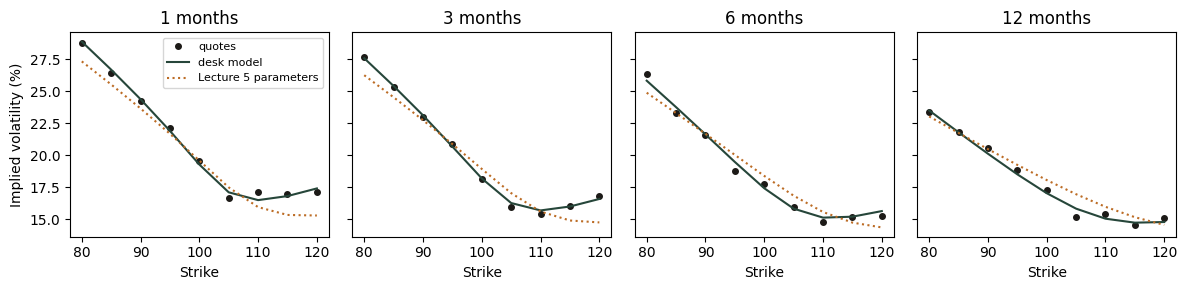

In [3]:
one_smile = dict(strikes=SHEET["strikes"], maturities=SHEET["maturities"][ATM[0]:ATM[0]+1],
                 vols=SHEET["vols"][ATM[0]:ATM[0]+1])
SMILE_FIT, SMILE_RMSE = calibrate(one_smile, V0)
LECTURE5_RMSE = sheet_rmse(Heston(v0=V0), SHEET)
print("Three-month smile only:", {k: round(v, 3) for k, v in SMILE_FIT.items()}, f"| RMSE {SMILE_RMSE:.2f}")
print(f"Lecture 5 parameters on the whole sheet: RMSE {LECTURE5_RMSE:.2f} vol points")
fig, axes = plt.subplots(1, len(SHEET["maturities"]), figsize=(12, 3), sharey=True)
fitted = sheet_vols(MODEL, SHEET); lecture5 = sheet_vols(Heston(v0=V0), SHEET)
for j, ax in enumerate(axes):
    ax.plot(SHEET["strikes"], 100*SHEET["vols"][j], "o", color="#1C1A17", ms=4, label="quotes")
    ax.plot(SHEET["strikes"], 100*fitted[j], color="#26463A", label="desk model")
    ax.plot(SHEET["strikes"], 100*lecture5[j], ":", color="#BC6C25", label="Lecture 5 parameters")
    ax.set(title=f"{12*SHEET['maturities'][j]:.0f} months", xlabel="Strike")
axes[0].set_ylabel("Implied volatility (%)"); axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "calibration.png", dpi=160); plt.show()

### Answer — Brief 0 (M1, M2)

**Why implied volatility, and why several starts (M1).** Prices differ by two orders of magnitude across the sheet (cents in the short-dated wings, about 8 for the 12-month at-the-money call), so a least-squares fit in prices would be dominated by the expensive, high-vega quotes. Quote noise is also stated in volatility points (half-spread $\approx0.3$), and $\sigma^{\rm model}-\sigma^{\rm quote}\approx(\text{price error})/\text{vega}$, so implied-volatility residuals put every quote on the same noise scale. The problem is non-convex, with a flat $\kappa$–$\bar v$ valley and bounds, so a single start can stop at a poor local minimum: we run four starts and keep the lowest cost.

**Judging the fit.** The RMSE is 0.32 vol points, about one half-spread, so the residuals are the size of the quote noise. With 36 quotes and four parameters, a much smaller RMSE would suggest fitting noise; a much larger one would say the model misses the surface (Lecture 5's parameters give 0.97). Desk model: $\kappa=1.3693$, $\bar v=0.0449$, $\xi=0.6886$, $\rho=-0.5911$, with $v_0=0.04$ observed. Feller's condition fails ($2\kappa\bar v=0.123<\xi^2=0.474$), so the raw Euler variance can go negative: the simulator keeps the raw $v$ and uses $v^+$ in the coefficients.

**What one smile cannot separate (M2).** The three-month fit moves to $\kappa=0.10$ (the lower bound of the search) and $\bar v=0.075$ yet fits with RMSE 0.14, while the full sheet gives $\kappa=1.3693$, $\bar v=0.0449$. One maturity $T=0.25$ sees the variance path mainly through its expected time-average
$$\bar V=\bar v+(v_0-\bar v)\,\frac{1-e^{-\kappa T}}{\kappa T},$$
which is 0.0404 for the single-smile fit and 0.0408 for the full-sheet fit: very different $(\kappa,\bar v)$, almost the same smile. That is a flat valley, not a precise estimate. $\rho$ (skew) is pinned: the two fits agree to three decimals (−0.591 vs −0.5911); $\xi$ (curvature) moves by about 9%. Maturities from one to twelve months show how level and skew decay with the horizon, where $e^{-\kappa T}$ is no longer close to 1, so the term structure separates the speed $\kappa$ from the level $\bar v$.

**History versus pricing measure.** A change of measure changes drifts, not volatilities or correlations. A price history (with the variance observed) can therefore identify $\xi$, $\rho$ and $v_0$ through quadratic variation and covariation. It cannot identify $\kappa$ and $\bar v$ as they enter pricing: under $\mathbb Q$ they include the variance risk premium (for a premium proportional to $v$: $\kappa^{\mathbb Q}=\kappa^{\mathbb P}+\lambda$, $\bar v^{\mathbb Q}=\kappa^{\mathbb P}\bar v^{\mathbb P}/(\kappa^{\mathbb P}+\lambda)$), and the stock drift is replaced by the interest rate. Those belong to the pricing measure and can only be read from option prices.

**Why the premium is a quote.** The premium is what the client pays, and it is the same for every policy. Taking it from the model would build the calibration error into every P&L: a misfit of one half-spread (0.3 vol points) is worth about $0.3\times0.20=0.06$ at the three-month at-the-money strike (vega $\approx0.20$ per vol point). That is the size of the mean P&L shortfall seen later (about $-0.06$ for every hedge), which we do not recentre: it is a level offset common to all policies and says nothing about hedging skill. A model premium would also make every hedge fair on the training paths by construction and hide what the desk really faces, a market price that differs from the model.

## Brief 1 — Make the position self-financing

You receive the quoted premium $c_0$, the same for every policy. A positive holding means long stock.
In the ledger, spot has shape (paths,N+1) and phi has shape (paths,N).
Return two tensors of shape (paths,): terminal P&L and total paid costs.

**Task A1.** Implement gains, call payoff, opening/rebalancing/liquidation costs,
using PyTorch operations so the output remains differentiable in phi.
With cost rate $c$, the paid amount is
$$c\left[S_0|\phi_1|+\sum_{k=1}^{N-1}S_k|\phi_{k+1}-\phi_k|
                  +S_N|\phi_N|\right].$$
Never convert a training tensor to NumPy, and never detach it.

In [4]:
def ledger(phi, spot, premium, strike, cost=0.0):
    """Return terminal P&L and paid costs; include initial trade and liquidation."""
    gains = (phi * (spot[:, 1:] - spot[:, :-1])).sum(dim=1)               # sum_k phi_{k+1} (S_{k+1} - S_k)
    payoff = torch.relu(spot[:, -1] - strike)                             # (S_N - K)^+, cash settled
    opening = spot[:, 0] * phi[:, 0].abs()                                # S_0 |phi_1|
    rebalancing = (spot[:, 1:-1] * (phi[:, 1:] - phi[:, :-1]).abs()).sum(dim=1)   # S_k |phi_{k+1} - phi_k|, k = 1..N-1
    liquidation = spot[:, -1] * phi[:, -1].abs()                          # S_N |phi_N|
    paid = cost * (opening + rebalancing + liquidation)
    return premium + gains - payoff - paid, paid

toy_s = torch.tensor([[100., 110., 105.]], dtype=torch.float64)
toy_h = torch.tensor([[0.5, 0.25]], dtype=torch.float64, requires_grad=True)
toy_x, toy_c = ledger(toy_h, toy_s, 5.0, 100., 0.01)
assert np.allclose(toy_c.detach(), [1.0375])
assert np.allclose(toy_x.detach(), [2.7125])
toy_x.sum().backward()
assert np.allclose(toy_h.grad, [[7.9, -4.95]])
z_x, z_c = ledger(torch.zeros_like(toy_h), toy_s, 5.0, 100., 0.01)
assert np.allclose(z_x, [0.0]) and np.allclose(z_c, [0.0])
print("✓ A1: cash balance, cost timing and gradients.")

✓ A1: cash balance, cost timing and gradients.


### Answer — A1 (ledger)

**Hand check** of the path $(100,110,105)$, holdings $(0.5,0.25)$, premium $5$, strike $100$, cost rate $1\%$:

- gains: $0.5(110-100)+0.25(105-110)=5-1.25=3.75$
- payoff: $(105-100)^+=5$
- costs: $0.01\,[\,100\cdot0.5+110\cdot\lvert0.25-0.5\rvert+105\cdot0.25\,]=0.01\,(50+27.5+26.25)=1.0375$
- terminal P&L: $5+3.75-5-1.0375=2.7125$

These are the values asserted in the cell (`1.0375` and `2.7125`). The asserted gradient follows the same way: $\partial X/\partial\phi_1=10-0.01\,(100+110)=7.9$ and $\partial X/\partial\phi_2=-5-0.01\,(-110+105)=-4.95$; the sign of the rebalancing trade enters the derivative, which is why the ledger uses `abs` on torch tensors and never leaves PyTorch.

**Why not tomorrow's price?** The holding chosen at $t_k$ must depend only on information available at $t_k$. If $\phi_{k+1}$ could use $S_{k+1}$, the gain $\phi_{k+1}(S_{k+1}-S_k)$ would no longer be a martingale difference: for instance $\phi_{k+1}=\mathrm{sign}(S_{k+1}-S_k)$ earns $\lvert S_{k+1}-S_k\rvert>0$ on average, a profit no desk can implement, and every risk score would be meaningless. Column $k$ of `phi` is therefore matched with the increment from $k$ to $k+1$, and C2 tests rules for violations.

**Task A2.** The pricer supplies $C_S$ and $C_v$ (derivative with respect to
**variance**, not volatility). Return the continuous-time quadratic hedge.
Derive it in the report by projecting the claim's Brownian exposure onto that
of the stock. Explain why negative correlation usually reduces this call hedge
relative to $C_S$, and identify the remaining Brownian exposure.

The supplied driver evaluates both formulas at current state only and rebalances
daily. Its output is a benchmark, not an exact optimum for the discrete simulator.

In [5]:
def quadratic_position(spot, delta, variance_greek, model=MODEL):
    # h_quad = C_S + rho * xi * C_v / S  (C_v is the derivative with respect to variance)
    return delta + model.rho * model.xi * variance_greek / spot

assert np.allclose(quadratic_position(np.array([100.]), np.array([0.6]),
                                    np.array([20.]), Heston()), [0.53])
assert np.allclose(quadratic_position(100., 0.6, 20., Heston(rho=0.0)), 0.6)
print("✓ A2: units and zero-correlation limit.")

def formula_policies(s, v, model=MODEL):
    delta = np.empty((len(s), model.steps))
    quadratic = np.empty_like(delta)
    for k in range(model.steps):
        tau = model.expiry * (model.steps-k) / model.steps
        for start in range(0, len(s), 600):
            sl = slice(start, start+600)
            _, cs, cv = heston_greeks(s[sl, k], np.maximum(v[sl, k], 0.), tau, model=model)
            delta[sl, k] = cs
            quadratic[sl, k] = quadratic_position(s[sl, k], cs, cv, model)
    assert np.isfinite(delta).all() and np.isfinite(quadratic).all()
    return delta, quadratic

def account(phi, s, cost=0.0):
    with torch.no_grad():
        x, paid = ledger(torch.as_tensor(phi, dtype=torch.float64),
                         torch.as_tensor(s, dtype=torch.float64),
                         PREMIUM, MODEL.strike, cost)
    return {"pnl": x.numpy(), "cost": paid.numpy()}

def metrics(result):
    x = result["pnl"]
    return dict(mean=float(x.mean()), rmse=float(np.sqrt(np.mean(x*x))),
                sd=float(x.std(ddof=1)), cvar95=float(cvar_numpy(-x)),
                cost=float(result["cost"].mean()))

def table(results):
    print(f"{'policy':30s} {'mean':>8s} {'RMSE':>8s} {'SD':>8s} {'CVaR95':>8s} {'cost':>8s}")
    for name, result in results.items():
        m = metrics(result)
        print(f"{name:30s} " + " ".join(f"{m[k]:8.3f}" for k in m))

✓ A2: units and zero-correlation limit.


### Answer — A2 (quadratic hedge)

**Derivation.** Let $V_t=C(t,S_t,v_t)$ be the model value of the claim. Under $\mathbb Q$ with zero rates it is a martingale, so all $dt$ terms in Itô's formula cancel (the pricing PDE) and
$$dV=C_S\,dS+C_v\,dv+(\dots)\,dt=\sqrt v\,S\,C_S\,dW^S+\sqrt v\,\xi\,C_v\,dW^v .$$
Insert $dW^v=\rho\,dW^S+\sqrt{1-\rho^2}\,dW^\perp$:
$$dV=\sqrt v\,\bigl(S\,C_S+\rho\,\xi\,C_v\bigr)\,dW^S+\sqrt v\,\xi\sqrt{1-\rho^2}\,C_v\,dW^\perp .$$
A holding $\phi$ in the stock earns $\phi\,dS=\phi\,S\sqrt v\,dW^S$, which loads only on $dW^S$. Matching the $dW^S$ exposure (equivalently, projecting $dV$ on $dS$, $\phi=\mathrm{Cov}(dV,dS)/\mathrm{Var}(dS)$) gives
$$\phi\,S\sqrt v=\sqrt v\,(S\,C_S+\rho\,\xi\,C_v)\quad\Longrightarrow\quad h_{\rm quad}=C_S+\rho\,\xi\,\frac{C_v}{S}.$$

**Remaining exposure.** Stock and cash cannot remove $\sqrt v\,\xi\sqrt{1-\rho^2}\,C_v\,dW^\perp$, a volatility ("vega") exposure orthogonal to the stock's Brownian motion, with variance rate $(1-\rho^2)\,\xi^2\,v\,C_v^2$. With $\rho=-0.5911$, $\rho^2=0.349$: about 35% of the variance of the vega term is hedged by the correction and about 65% remains.

**Sign.** For a call $C_v>0$; with $\xi>0$, $S>0$ and $\rho<0$ the correction is negative, so $h_{\rm quad}<C_S$ (the check in the cell moves $0.60$ to $0.53$). When the stock falls, variance tends to rise and lifts the call's value, so the call loses less than $C_S\,\Delta S$ and fewer shares are needed to offset its $dW^S$-part.

**$\rho=0$.** The correction vanishes and $h_{\rm quad}=C_S$. The market is still not complete: the whole exposure $\sqrt v\,\xi\,C_v\,dW^v$ is orthogonal to the stock. Completeness would need $\lvert\rho\rvert=1$ (or $C_v=0$).

**A benchmark, not the optimum.** The formula solves the continuous-time problem with continuous trading. The simulator is an Euler scheme with 63 dates and a truncated variance, and the supplied driver evaluates the formula at the current state only. Two errors remain and they differ in nature: *incomplete-market risk* (the $dW^\perp$ term, which does not shrink with more frequent trading) and *time-discretisation error* (gamma over a finite step, which vanishes as the number of dates grows). A daily-rebalanced formula carries both.

**Prediction.** Here $h_{\rm quad}<h_\Delta$ and the quadratic hedge removes the part of the vega risk that moves with the stock, so we expect RMSE(quadratic) < RMSE(delta) $\ll$ RMSE(unhedged). On the market's paths (test cell): 1.423 < 1.761 $\ll$ 4.804; the correction removes about 35% of delta's mean-square error.

**"Delta is the number of shares, so there is nothing to estimate."** In Heston $C_S$ holds the variance fixed, but the variance moves with the stock ($\rho\neq0$), so the minimum-variance share count is $C_S+\rho\xi C_v/S$. Both $C_S$ and $C_v$ depend on $(\kappa,\bar v,\xi,\rho)$, which must be calibrated, with $\kappa$ and $\bar v$ weakly identified (M2), and on the current variance. A "delta" is a model output carrying calibration and model error, not an observable.

## Brief 2 — Learn the hedge backwards

First calibrate on the 27-state tree from the notes, under its martingale
measure $\mathbb Q^0$. This is exact, with no sampling error.
**Task B1:** return the intercept and slope of the weighted regression of
value on ds. The driver compares your backward solution with a single global
weighted projection onto cash and all predictable stock gains.

In [6]:
def node_regression(ds, value, p):
    ds, value, p = (np.asarray(a, dtype=float) for a in (ds, value, p))
    p = p / p.sum()
    mean_ds, mean_value = p @ ds, p @ value
    slope = (p @ ((ds - mean_ds) * (value - mean_value))) / (p @ (ds - mean_ds) ** 2)   # Cov_p(V, dS) / Var_p(dS)
    intercept = mean_value - slope * mean_ds                                            # = E_p[V] when E_p[dS] = 0
    return float(intercept), float(slope)

def calibrate_tree():
    returns = np.array([-0.10, 0.0, 0.15])
    tilt = brentq(lambda a: np.exp(-a*returns) @ returns, -50., 50.)
    q = np.exp(-tilt*returns); q /= q.sum()
    paths = list(itertools.product(range(3), repeat=3))
    price = lambda w: 100. * np.prod([1+returns[j] for j in w])
    payoff = np.array([max(price(w)-100., 0.) for w in paths])
    weights = np.array([np.prod(q[list(w)]) for w in paths])
    values = dict(zip(paths, payoff)); holdings = {}
    for k in reversed(range(3)):
        previous = {}
        for w in itertools.product(range(3), repeat=k):
            child = np.array([values[w+(j,)] for j in range(3)])
            previous[w], holdings[w] = node_regression(price(w)*returns, child, q)
        values = previous
    nodes = [w for k in range(3) for w in itertools.product(range(3), repeat=k)]
    gain_matrix = np.zeros((27, len(nodes)))
    for i, w in enumerate(paths):
        for j, node in enumerate(nodes):
            if w[:len(node)] == node:
                gain_matrix[i, j] = price(node)*returns[w[len(node)]]
    design = np.column_stack([np.ones(27), gain_matrix])
    root_w = np.sqrt(weights)
    global_fit = np.linalg.lstsq(design*root_w[:, None], payoff*root_w, rcond=None)[0]
    local = np.array([values[()]] + [holdings[w] for w in nodes])
    assert np.max(np.abs(design @ (local-global_fit))) < 1e-10
    error = design @ local - payoff
    assert abs(weights @ error) < 1e-10
    assert np.max(np.abs(design.T @ (weights*error))) < 1e-9
    assert abs(local[0]-6.9587) < 0.0001
    assert abs(weights @ error**2-3.5405) < 0.0001
    print(f"✓ B1: tree agrees with global projection; cash={local[0]:.6f}, MSE={weights @ error**2:.6f}")
    return dict(cash=float(local[0]), mse=float(weights @ error**2))

TREE_CHECK = calibrate_tree()

✓ B1: tree agrees with global projection; cash=6.958658, MSE=3.540497


### Answer — B1 (tree)

On the 27-state tree the node regressions are exact conditional projections: the slope at a node is $\mathrm{Cov}_q(V,\Delta S)/\mathrm{Var}_q(\Delta S)$ and the intercept is the $q$-mean of the child values. The driver then solves one global weighted least-squares problem on cash and every predictable gain, and finds the same coefficients to $10^{-10}$ with a residual orthogonal to cash and to each gain (the normal equations). Initial capital is 6.958658 and the mean-squared hedging error 3.540497 under $\mathbb Q^0$; it is positive because three branches and one stock leave the tree incomplete.

**Why this is stronger than a small training loss.** Both sides of the check are exact and independent of the code under test: the projection is the unique minimiser (up to null directions) and the orthogonality conditions are necessary and sufficient for it, so an error in the weights, the date order or the slope formula breaks them. A small training loss has no reference value; wrong code can also reach it (by leaking future information, for instance), and it does not say how far the result is from the optimum.

**Why not under the tree's uniform physical probabilities.** With probability $1/3$ on each branch the expected one-step return is $(-0.10+0+0.15)/3=+1.67\%$, so $\mathbb E[\Delta S\mid\mathcal F_k]\neq0$. Cash and stock gain are then no longer orthogonal, the one-step slopes no longer compose into the global mean-square minimiser (a mean–variance problem with drift needs extra terms), and the initial capital is not the expectation of the claim. The martingale property of $S$ under $\mathbb Q^0$ is what makes the stepwise regressions equal the global projection.

On Heston paths, most states are never repeated. Replace node-by-node conditional
expectations by regression on state functions. The provided basis returns:

* g: candidate hedge features; the holding is g times the date's coefficients;
* f: nuisance features for the conditional continuation level.

**Task B2.** Start with realised residual = payoff. Walk backwards.
At each date regress residual on the concatenated columns [f, g times ds], store
the coefficients on the g-times-ds columns, and subtract that date's realised
hedge gain from residual. Return the date-ordered coefficient list and final residual.

Keep the realised residual when stepping back. Replacing it by the fitted continuation
discards errors that matter for subsequent fits with limited bases. All fitting
uses training paths. Deployment uses only current-state hedge features.
Future payoffs are valid training targets; future states are invalid decision inputs.

In [7]:
def basis(s, v, k, name="rich", model=MODEL):
    tau = model.expiry*(model.steps-k)/model.steps
    sig = np.sqrt(np.maximum(v, 1e-6))
    d1 = (np.log(s/model.strike) + 0.5*sig**2*tau)/(sig*np.sqrt(tau))
    delta = ndtr(d1)
    correction = np.exp(-d1*d1/2)/np.sqrt(2*np.pi)*np.sqrt(tau)/sig
    x = (s-model.strike)/(model.spot*np.sqrt(model.theta*model.expiry))
    y = (v-model.theta)/model.theta
    if name == "compact":
        return np.column_stack([delta, np.ones_like(s)]), np.column_stack([np.ones_like(s), x, y])
    if name == "rich":
        return np.column_stack([delta, correction, np.ones_like(s)]), np.column_stack(
            [np.ones_like(s), x, y, x*x, x*y])
    raise ValueError(name)

def backward_fit(s, v, name="rich", model=MODEL):
    n_steps = model.steps
    assert s.shape[1] == n_steps + 1 and v.shape == s.shape
    ds = np.diff(s, axis=1)                                      # ds[:, k] = S_{k+1} - S_k
    residual = np.maximum(s[:, -1] - model.strike, 0.0)          # R_N = H
    coefficients = [None] * n_steps
    for k in range(n_steps - 1, -1, -1):
        g, f = basis(s[:, k], v[:, k], k, name, model)           # features known at t_k only
        design = np.column_stack([f, g * ds[:, k:k + 1]])        # [f_k, g_k * dS_{k+1}]
        solution = np.linalg.lstsq(design, residual, rcond=None)[0]   # minimum-norm if collinear (t_0)
        b = solution[f.shape[1]:]                                # keep the hedge coefficients b_k only
        coefficients[k] = b
        residual = residual - (g @ b) * ds[:, k]                 # realised residual R_k, not the fitted level
    return coefficients, residual

def regression_policy(coefficients, s, v, name, model=MODEL):
    return np.column_stack([np.einsum("ij,j->i", basis(s[:, k], v[:, k], k, name, model)[0], coefficients[k])
                            for k in range(model.steps)])

train_s, train_v = simulate(CFG["train"], 70000+CFG["seeds"][0], MODEL)
valid_s, valid_v = simulate(CFG["validation"], CFG["validation_seed"], MODEL)
valid_data = tensors(valid_s, valid_v, MODEL)
print("Computing formula benchmarks on validation paths...")
valid_delta, valid_quad = formula_policies(valid_s, valid_v)
reg_candidates = {}
for name in ["compact", "rich"]:
    coeff, residual = backward_fit(train_s, train_v, name)
    train_phi = regression_policy(coeff, train_s, train_v, name)
    assert np.allclose(residual, np.maximum(train_s[:, -1]-MODEL.strike, 0.) -
                       (train_phi*np.diff(train_s, axis=1)).sum(axis=1))
    val = account(regression_policy(coeff, valid_s, valid_v, name), valid_s)
    reg_candidates[name] = dict(coeff=coeff, validation=metrics(val)["rmse"])
REG_NAME = min(reg_candidates, key=lambda name: reg_candidates[name]["validation"])
REG_COEFF = reg_candidates[REG_NAME]["coeff"]
FORMULA_RMSE = metrics(account(valid_quad, valid_s))["rmse"]
assert reg_candidates[REG_NAME]["validation"] < 1.1*FORMULA_RMSE, \
    "The regression hedge is far worse than the formula: check the order and target of your backward fit."
print("✓ B2: residual identity; validation RMSE:", {k: round(v["validation"], 4) for k,v in reg_candidates.items()},
      f"(formula {FORMULA_RMSE:.4f})")
print("Selected basis:", REG_NAME)

Computing formula benchmarks on validation paths...
✓ B2: residual identity; validation RMSE: {'compact': 1.5068, 'rich': 1.4866} (formula 1.4680)
Selected basis: rich


### Answer — B2 (backward regression in Heston)

**Link to Theorem 3.9.** For a residual claim $R_{k+1}$ the one-step quadratic hedge is the conditional covariance/variance ratio
$$\phi^{*}_{k+1}=\frac{\mathrm{Cov}(R_{k+1},\Delta S_{k+1}\mid\mathcal F_k)}{\mathrm{Var}(\Delta S_{k+1}\mid\mathcal F_k)},\qquad R_k=R_{k+1}-\phi_{k+1}\Delta S_{k+1},\quad R_N=H,$$
and the regression of $R_{k+1}$ on $[f_k,\ g_k\Delta S_{k+1}]$ is its sample version. Because $\mathbb E[\Delta S_{k+1}\mid\mathcal F_k]=0$ under $\mathbb Q$, the level $f_k^\top a$ and the gain $g_k^\top b\,\Delta S_{k+1}$ are conditionally orthogonal: the nuisance features $f$ do not bias $b$, they only reduce the noise in its estimate.

**Three different errors.** (i) *Exact conditional projection*: $\phi^*$ above, a function of the whole state under the true law. (ii) *Finite-basis approximation*: restricting $\phi=g^\top b_k$ leaves a bias that more paths cannot remove. (iii) *Finite-sample estimation*: $b_k$ is estimated from 8,000 paths with one observation per continuous state; the noise shrinks with more paths, grows with the number of features and compounds backwards through the residuals.

**Why the realised residual.** The hedge at $t_k$ must neutralise the risk that the later, estimated hedges actually leave, $R_k=H-\sum_{j\ge k}\hat\phi_{j+1}\Delta S_{j+1}$ (the cell checks this identity). Replacing it by the fitted continuation level would erase the part the limited basis could not explain, so earlier dates would hedge a smoothed claim instead of the residual risk being carried.

**Future payoffs are targets, not inputs.** $R_{k+1}$ depends on the future path, which is legitimate as a training label for estimating conditional moments. At deployment only $g(S_k,v_k)$, the date and the frozen $b_k$ are used; a future price as an input would be look-ahead (C2). The coefficients must be frozen on new paths: refitting them on the test paths would fit that sample's own outcomes, so the score would measure fit rather than out-of-sample hedging, and in live trading the future payoff is unknown.

**Basis choice.** Validation RMSE: compact 1.5068, rich 1.4866 (formula 1.4680); we keep **rich**, chosen on validation only. A larger basis lowers each step's in-sample squared error (the spans are nested) but need not improve test RMSE: it adds estimation noise, and the test paths come from the market rather than the desk's model. On validation the gain is 1.3%; on the market's paths the regression ends slightly behind the formula (1.440 vs 1.423, see the test answer). At $t_0$ all paths share one state, so the features are collinear; `lstsq` returns the minimum-norm solution without inverting.

**Write before training a network.** Which inputs are measurable at the trading
date? Why does the martingale assumption justify the quadratic projection?
Why would changing the stock drift require revisiting the argument?
Predict the ordering of unhedged, Heston-delta, formula-quadratic and regression RMSE.

Full truncation uses $v^+=\max(v,0)$ in coefficients but retains raw $v$ in the
transition. Negative raw states are numerical states, not negative physical variances.
Formula Greeks use $v^+$; learned policies see raw $v$.

### Answer — "Write before training a network"

**Measurable at the trading date.** Functions of information up to $t_k$: the date (time to expiry), $S_k$ (scaled log-moneyness), the raw variance $v_k$ (observed here) and, for the recurrent network, the previous holding $\phi_k$. Not measurable: $S_{k+1}$, the payoff $(S_N-K)^+$, later variances, realised volatility or "crossed $K$ in the last month" (ex-post labels used only in F2) and the test-sample mean.

**Why the martingale assumption justifies the projection.** Under $\mathbb Q$ the stock has zero conditional drift, so cash and stock gain are orthogonal and the premium is $\mathbb E^{\mathbb Q}[H]$. The one-step minimum-variance hedge is then the conditional covariance/variance ratio of B2, the same stepwise ratios solve the global mean-square problem (exactly, on the tree), and fixed-premium MSE and variance share their minimisers because the mean P&L does not depend on the hedge.

**Why a different stock drift would force us to revisit it.** With $\mathbb E[\Delta S\mid\mathcal F_k]=\mu S_k\Delta t\neq0$ the intercept and the gain are correlated, the stepwise projection no longer minimises the terminal mean-square error (mean–variance hedging then needs a correction for the market price of risk), the fair premium is no longer $\mathbb E[H]$, and the mean P&L depends on the hedge, so MSE and variance have different minimisers. Training, validation and test paths are all under $\mathbb Q$ here, so the argument applies; under $\mathbb P$ it would have to be redone.

**Expected ranking.** RMSE: unhedged $\gg$ Heston delta $>$ quadratic formula $\lesssim$ regression, with the regression within a few percent of the formula (finite basis, 8,000 paths) and the MSE networks close to the formula. Frictionless CVaR network: a small CVaR gain over the formula with a larger standard deviation. With costs: formula + costs $\gg$ band $\gtrsim$ cost-aware networks. Observed on the market's paths: unhedged 4.804 > Heston delta 1.761 > regression 1.440 > formula 1.423. See the timing note in the research record below: this ordering is what theory and the *validation* scores (formula 1.4680 < rich regression 1.4866 < compact 1.5068) support.

## Brief 3 — What would count as evidence?

Training fits coefficients and weights; validation chooses a basis, checkpoints
and band widths. Test paths are generated only after those choices are frozen.
All policies then face the **same** test paths.

**Task C1.** Bootstrap metric(a)-metric(b) by resampling common path indices
for both arrays. Return estimate, se, and a percentile ci95.
This interval is conditional on fitted policies. It does not measure training
instability or model error. Individual training seeds are reported separately.

In [8]:
def paired_interval(a, b, metric, repeats=600, seed=8):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    assert a.ndim == 1 and a.shape == b.shape, "paired comparison needs the same paths in the same order"
    rng = np.random.default_rng(seed)
    n = len(a)
    diffs = np.empty(repeats)
    for r in range(repeats):
        idx = rng.integers(0, n, size=n)                         # the SAME resampled paths for both policies
        diffs[r] = metric(a[idx]) - metric(b[idx])
    return dict(estimate=float(metric(a) - metric(b)),
                se=float(np.std(diffs, ddof=1)),
                ci95=[float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))])

same = paired_interval(np.arange(20.), np.arange(20.), np.mean, repeats=50)
shift = paired_interval(np.arange(20.)+2., np.arange(20.), np.mean, repeats=50)
assert same["se"] == 0 and same["ci95"] == [0., 0.]
assert np.allclose(shift["ci95"], [2., 2.])
print("✓ C1: pairing preserves identical samples and constant differences.")

✓ C1: pairing preserves identical samples and constant differences.


**Task C2.** Test a frozen trading rule for look-ahead.
Make copies of s and v. Multiply all stock observations strictly after date k
by 1.2 and add 0.05 to variance observations strictly after k.
Return whether holdings through column k are unchanged (within numerical tolerance).
Do not refit the rule. A passing perturbation test is useful evidence, not a proof.

In [9]:
def prefix_check(rule, s, v, k):
    s_base, v_base = np.array(s, dtype=float), np.array(v, dtype=float)       # private copies
    s_pert, v_pert = s_base.copy(), v_base.copy()
    s_pert[:, k + 1:] *= 1.2                                     # stock observations strictly after t_k
    v_pert[:, k + 1:] += 0.05                                    # variance observations strictly after t_k
    base, pert = np.asarray(rule(s_base, v_base)), np.asarray(rule(s_pert, v_pert))
    # rtol=0: an absolute tolerance only, so a small relative leak cannot hide behind allclose's default
    return bool(np.allclose(base[:, :k + 1], pert[:, :k + 1], rtol=0.0, atol=1e-10, equal_nan=True))

reg_rule = lambda s,v: regression_policy(REG_COEFF, s, v, REG_NAME)
leaky_rule = lambda s,v: np.broadcast_to((s[:, -1] > MODEL.strike)[:, None],
                                        (len(s), MODEL.steps)).astype(float)
assert prefix_check(reg_rule, valid_s[:50], valid_v[:50], 20)
assert not prefix_check(leaky_rule, valid_s[:50], valid_v[:50], 20)
print("✓ C2: frozen regression passes; a terminal-price rule fails.")

✓ C2: frozen regression passes; a terminal-price rule fails.


### Answer — C1 and C2

**C1: why pairing.** Both policies face the same paths, so their P&Ls share the dominant randomness (the stock path and hence the payoff). For paired differences $\mathrm{Var}(D)=\mathrm{Var}(a)+\mathrm{Var}(b)-2\,\mathrm{Cov}(a,b)$ is far smaller than the unpaired variance, and resampling the *same* path indices for both arrays keeps that dependence in every bootstrap replicate; the metric (MSE or CVaR) is recomputed on each resample and the 95% interval is the 2.5–97.5 percentile range of the differences. **Scope:** fresh-path sampling error conditional on the two fitted policies. It does not include retraining variability (the other seeds are shown separately), simulation bias, calibration error or model misspecification. The six intervals are pointwise and exploratory, not simultaneous: six independent 95% intervals would miss at least one truth about a quarter of the time, so a borderline interval deserves caution.

**C2: predictability versus statistical separation.** *Predictability* is a property of the deployed rule: the holding at $t_k$ depends only on information up to $t_k$. *Statistical separation* is a property of the workflow: parameters were fitted and tuned on training and validation paths, never on the test paths. A rule can pass one and fail the other. A regression whose coefficients were refitted on the test paths still passes the prefix check, since its holdings at $t_k$ use only $(S_k,v_k)$, yet its test score is contaminated. A rule trained only on clean data but using the terminal price fails the prefix check, as the supplied leaking rule does. The perturbation (stock $\times1.2$, variance $+0.05$ after date $k$) accepts our frozen regression. It is one finite perturbation: a rule that depends on the future in a way that this change does not alter would pass, so the check supports code review but proves nothing for every possible path.

## Brief 4 — Train the trading rule

A small shared network sees time to expiry, scaled log-moneyness and variance.
It outputs shares. It never sees a formula hedge as a label. Training differentiates
the **terminal hedging loss** through every decision on the path.

**Task D1.** For the network with previous-holding input, start at zero and make
decisions in date order. Append previous holding minus 0.5 as the fourth input.
Stack outputs into (paths,N). Keep the graph through previous holdings.
The market-only case is supplied.

This state captures immediate trading costs. It is not generally sufficient for
unrestricted terminal CVaR: accumulated net gains can also matter.

In [10]:
def policy_holdings(net, batch):
    x = batch["features"]
    if not net.holding:
        return net(x)
    prev_h = torch.zeros(x.shape[0], device=x.device, dtype=x.dtype)         # phi_0 = 0
    holdings = []
    for k in range(x.shape[1]):                                              # dates in order t_0, ..., t_{N-1}
        inputs = torch.cat([x[:, k, :], (prev_h - 0.5).unsqueeze(-1)], dim=-1)
        prev_h = net(inputs)                                                 # no detach: the graph runs through earlier holdings
        holdings.append(prev_h)
    return torch.stack(holdings, dim=1)                                      # (paths, N)

class RecurrenceProbe(torch.nn.Module):
    holding = True
    def __init__(self):
        super().__init__()
        self.a = torch.nn.Parameter(torch.tensor(0.2))
    def forward(self, x):
        return self.a + 0.5*(x[:, -1]+0.5)

probe = RecurrenceProbe()
probe_phi = policy_holdings(probe, {"features": torch.zeros(1, 3, 3)})
assert torch.allclose(probe_phi, torch.tensor([[0.2, 0.3, 0.35]]))
probe_phi[:, -1].sum().backward()
assert abs(probe.a.grad.item()-1.75) < 1e-6
print("✓ D1: decisions and gradient through earlier positions.")

✓ D1: decisions and gradient through earlier positions.


**Task D2.** Implement empirical 95% loss CVaR as the mean of the worst
tail times batch-size observations. Require this count to be a positive integer.
Use differentiable PyTorch operations. This handles atoms by allocating the correct
boundary mass, unlike averaging all losses strictly above a quantile.

In the notes' convention $\mathrm{CVaR}_{0.95}(X)$ takes a P&L $X$; this function
takes **loss** $L=-X$. Explain its equivalence to
$\min_z\{z+\mathbb E[(L-z)^+]/0.05\}$ on the batch.
What goes wrong when a jointly trained $z$ remains below all observed losses?
Profiling batches avoids that lag, but is not an unbiased population-CVaR gradient.

In [11]:
def tail_objective(loss, tail=0.05):
    m = tail * loss.numel()
    k = int(round(m))
    assert abs(m - k) < 1e-9 and k >= 1, f"tail * batch size = {m} must be a positive integer"
    # mean of the k worst losses: exact boundary mass because k is an integer; gradient 1/k on each selected path
    return torch.topk(loss.reshape(-1), k).values.mean()

atoms = torch.tensor([0.]*90+[10.]*7+[100.]*3, requires_grad=True)
atomic_tail = tail_objective(atoms)
assert abs(atomic_tail.item()-64.) < 1e-6
atomic_tail.backward()
assert abs(atoms.grad.sum().item()-1.) < 1e-6
assert np.allclose(tail_objective(atoms.detach()+7.).item(), 71.)
z = torch.quantile(atoms.detach(), 0.95, interpolation="lower")
assert torch.allclose(atomic_tail.detach(), z+torch.relu(atoms.detach()-z).mean()/0.05)
print("✓ D2: boundary atoms, cash shift and RU value.")

✓ D2: boundary atoms, cash shift and RU value.


### Answer — D1 and D2

**D1.** The terminal loss depends on $\phi_{k+1}$ directly through its gain and cost, and indirectly because the network at date $k+1$ takes $\phi_{k+1}$ as an input. `detach()` would cut the second path and give the wrong derivative; the probe's holdings $(0.2,0.3,0.35)$ have $d\phi_3/da=1+0.5+0.25=1.75$ with the graph kept, but $1$ if it were cut.

**D2: Rockafellar–Uryasev.** For a loss $L$ and $\alpha=0.05$ let $R(z)=z+\frac1\alpha\,\mathbb E[(L-z)^+]$. It is convex and piecewise linear in $z$, with right derivative $1-\mathbb P(L>z)/\alpha$ and left derivative $1-\mathbb P(L\ge z)/\alpha$. A minimiser needs left derivative $\le0\le$ right derivative:
$$\mathbb P(L>z^*)\le\alpha\le\mathbb P(L\ge z^*),$$
so $z^*$ is the $(1-\alpha)$-quantile (the VaR). Using $\mathbb E[(L-z^*)^+]=\mathbb E[L;\,L>z^*]-z^*\,\mathbb P(L>z^*)$,
$$R(z^*)=\frac1\alpha\Bigl\{\mathbb E[L;\,L>z^*]+z^*\bigl(\alpha-\mathbb P(L>z^*)\bigr)\Bigr\},$$
the average of the worst $\alpha$ of the probability mass: everything strictly above $z^*$, plus just enough of the atom at $z^*$ to complete mass $\alpha$. On a batch of $n$ losses with $k=\alpha n$ an integer, this is the mean of the $k$ largest losses, which is `topk(...).mean()` (the code asserts that $\alpha n$ is a positive integer; each selected path gets gradient weight $1/k$).

**Boundary mass in the check batch** (90 zeros, seven 10s, three 100s; $k=5$): $\mathbb P(L>10)=0.03$, so the tail takes $0.05-0.03=0.02$ from the atom at 10 of mass 0.07, i.e. $2/7$ of it:
$$\tfrac{1}{5}\,(3\cdot100+2\cdot10)=64=10+\tfrac{0.03\cdot90}{0.05}=10+54 .$$
Averaging only the losses strictly above the quantile would give 100, the wrong answer for CVaR at level 5%. Adding a constant cash $c$ to the P&L shifts every loss by $-c$ and the objective by $-c$ (the asserted 64 → 71 with $+7$ on the losses is the same fact with the opposite sign).

**A stale threshold below every loss.** If $z<\min L$ then $(L-z)^+=L-z$ for every path and $R(z)=\mathbb E[L]/\alpha-z\,(1/\alpha-1)$. The gradient with respect to the network is $\frac1\alpha\nabla\mathbb E[L]=20\,\nabla\mathbb E[L]$: training minimises the *mean* loss, 20 times too loudly, with no focus on the tail. A jointly trained $z$ only feels $\partial R/\partial z=1-1/\alpha=-19$ and moves at about the learning rate (0.002) per step, so it needs a very long time to reach a loss quantile of a few units; the lag is the failure. Profiling $z$ out inside each batch (the batch quantile, as `tail_objective` does) removes the lag, but then the gradient is that of the batch CVaR: it selects the tail with the same sample it differentiates, and a minimum of sample objectives is biased downwards, so it is not an unbiased gradient of the population CVaR (the bias shrinks as the batch grows; with 1,000 paths the tail has 50 observations).

**Task D3.** Complete one stochastic-gradient step:
construct holdings, compute P&L with your ledger, choose MSE or loss CVaR,
clear old gradients, backpropagate, clip gradient norm at 10, and update Adam.
Return the detached objective as a Python float. Use batch paths only.

In [12]:
def training_step(net, batch, optimizer, objective, cost, premium):
    phi = policy_holdings(net, batch)
    pnl, _ = ledger(phi, batch["spot"], premium, MODEL.strike, cost)
    if objective == "mse":
        loss = (pnl ** 2).mean()                                 # fixed-premium second moment
    elif objective == "cvar":
        loss = tail_objective(-pnl, CFG["tail"])                 # worst 5% of the loss L = -X
    else:
        raise ValueError(f"unknown objective {objective!r}")
    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(net.parameters(), 10.0)
    optimizer.step()
    return float(loss.detach())

def network_result(net, data, cost=0.0):
    results = {"pnl": [], "cost": []}
    net.eval()
    with torch.no_grad():
        for start in range(0, len(data["spot"]), 1000):
            batch = {key: value[start:start+1000] for key,value in data.items()}
            pnl, paid = ledger(policy_holdings(net, batch), batch["spot"],
                               PREMIUM, MODEL.strike, cost)
            results["pnl"].append(pnl.numpy().astype(float))
            results["cost"].append(paid.numpy().astype(float))
    return {key: np.concatenate(value) for key,value in results.items()}

def objective_score(result, objective):
    return float(np.mean(result["pnl"]**2)) if objective == "mse" else float(cvar_numpy(-result["pnl"]))

def train_policy(net, data, valid, objective, cost, steps, seed):
    generator = torch.Generator().manual_seed(seed)
    optimizer = torch.optim.Adam(net.parameters(), lr=CFG["learning_rate"])
    best_state = copy.deepcopy(net.state_dict())
    best = objective_score(network_result(net, valid, cost), objective)
    history = [dict(step=0, validation=best, training=None)]
    best_step = 0
    for step in range(1, steps+1):
        net.train()
        idx = torch.randint(len(data["spot"]), (CFG["batch"],), generator=generator)
        batch = {key: value[idx] for key,value in data.items()}
        loss = training_step(net, batch, optimizer, objective, cost, PREMIUM)
        lr = CFG["learning_rate"]*(0.1+0.45*(1+math.cos(math.pi*step/steps)))
        for group in optimizer.param_groups:
            group["lr"] = lr
        if step % 100 == 0 or step == steps:
            score = objective_score(network_result(net, valid, cost), objective)
            history.append(dict(step=step, validation=score, training=loss))
            if score < best:
                best, best_step = score, step
                best_state = copy.deepcopy(net.state_dict())
    net.load_state_dict(best_state)
    return dict(best_step=best_step, best_validation=best, history=history)

## Brief 5 — Execution changes the problem

Trading now costs 50 basis points of notional at every trade, including opening
and liquidation. Before using another network, try a two-parameter competitor.
**Task E1:** at each date clip the previous holding to the interval
[formula minus lower, formula plus upper], starting at zero.
A grid search chooses the widths on validation CVaR only.
The two cost networks use the same objective and number of updates.
Both start from that seed's frictionless CVaR fit.

In [13]:
def band_policy(target, lower, upper):
    target = np.asarray(target, dtype=float)
    holdings = np.empty_like(target)
    previous = np.zeros(target.shape[0])                         # phi_0 = 0
    for k in range(target.shape[1]):
        # no trade while the old position sits inside [h_k - lower, h_k + upper]; otherwise trade to the nearer edge
        current = np.clip(previous, target[:, k] - lower, target[:, k] + upper)
        holdings[:, k] = current
        previous = current
    return holdings

assert np.allclose(band_policy(np.array([[0.5, 0.52, 0.8]]), 0.1, 0.1), [[0.4, 0.42, 0.7]])
assert np.allclose(band_policy(np.array([[0.5, 0.3, 0.32]]), 0.1, 0.05), [[0.4, 0.35, 0.35]]), \
    "Use the lower width below the target and the upper width above it."
assert np.allclose(band_policy(valid_quad, 0., 0.), valid_quad)
band_choices = []
for a, b in itertools.product(CFG["band_grid"], repeat=2):
    score = metrics(account(band_policy(valid_quad, a, b), valid_s, CFG["rate"]))["cvar95"]
    band_choices.append((score, a, b))
BAND_SCORE, BAND_LOWER, BAND_UPPER = min(band_choices)
print(f"✓ E1: selected band [{BAND_LOWER:.2f}, {BAND_UPPER:.2f}], validation CVaR={BAND_SCORE:.3f}")

✓ E1: selected band [0.04, 0.08], validation CVaR=5.064


### Answer — E1 (band)

**When it trades.** At date $k$ the rule keeps the old position $\phi_k$ if it lies inside $[h_k-a,\ h_k+b]$; otherwise it trades only to the nearer edge: sell down to $h_k+b$ if $\phi_k>h_k+b$, buy up to $h_k-a$ if $\phi_k<h_k-a$. It does not trade to the target $h_k$, because the cost is proportional to $\lvert\phi_{k+1}-\phi_k\rvert$ and the smallest trade that restores the tolerance is the cheapest.

**Why the current position matters.** The cost depends on the change from the position already held, so the decision depends on $\phi_k$ as well as on the market state: the rule has memory even though it has two parameters and no learning.

**Zero width.** With $a=b=0$, $\mathrm{clip}(\phi_k,h_k,h_k)=h_k$: the frictionless formula (asserted in the cell).

**Result.** The validation grid selected $a=0.04$, $b=0.08$ shares (validation CVaR 5.064). It is a feasible tuned rule, not a global optimum: the grid is coarse ($0,\,0.04,\,0.08,\,0.12,\,0.2,\,0.3$) and the widths are constants rather than functions of time or state.

### Run the research

Train four policies per seed: MSE without costs; CVaR without costs; CVaR with
costs and market inputs; CVaR with costs and previous holding.
Full mode uses three independent training samples and initialisations, with common
validation paths. Do not choose a seed after viewing test performance.
No assertion demands that a network win.

In [14]:
models, fit_records = {}, {}
started = time.time()
for seed in CFG["seeds"]:
    torch.manual_seed(seed)
    s, v = simulate(CFG["train"], 70000+seed, MODEL)
    train_data = tensors(s, v, MODEL)
    mse = HedgeNet()
    probe_before = {key: value.clone() for key,value in mse.state_dict().items()}
    record_mse = train_policy(mse, train_data, valid_data, "mse", 0.,
                              CFG["mse_steps"], seed+100)
    assert any(not torch.equal(probe_before[key], value) for key,value in mse.state_dict().items())
    tail = copy.deepcopy(mse)
    record_tail = train_policy(tail, train_data, valid_data, "cvar", 0.,
                               CFG["tail_steps"], seed+200)
    no_memory = copy.deepcopy(tail)
    record_no_memory = train_policy(no_memory, train_data, valid_data, "cvar", CFG["rate"],
                                    CFG["cost_steps"], seed+300)
    memory = warm_start(tail, holding=True)
    record_memory = train_policy(memory, train_data, valid_data, "cvar", CFG["rate"],
                                 CFG["cost_steps"], seed+300)
    models[seed] = dict(mse=mse, tail=tail, cost_market=no_memory, cost_memory=memory)
    fit_records[seed] = dict(mse=record_mse, tail=record_tail,
                             cost_market=record_no_memory, cost_memory=record_memory)
    for name in ["tail", "cost_market", "cost_memory"]:
        assert fit_records[seed][name]["best_step"] > 0, \
            f"{name}: CVaR training never improved on its starting point. Check the sign of the loss in training_step."
    print(f"Seed {seed}: " + ", ".join(f"{name}={r['best_validation']:.3f}" for name,r in fit_records[seed].items()))
    print(f"Elapsed: {time.time()-started:.1f}s", flush=True)
print("✓ D3: fitted policies produced by your stochastic-gradient step.")

Seed 11: mse=2.230, tail=3.477, cost_market=5.108, cost_memory=5.008
Elapsed: 129.4s
Seed 22: mse=2.244, tail=3.433, cost_market=5.116, cost_memory=5.027
Elapsed: 248.2s
Seed 33: mse=2.216, tail=3.411, cost_market=5.064, cost_memory=4.986
Elapsed: 341.9s
✓ D3: fitted policies produced by your stochastic-gradient step.


### Answer — D3 and the training run

**Why CVaR can improve while the standard deviation worsens.** The standard deviation weighs both sides of the P&L equally; CVaR looks only at the worst 5%. A policy can accept more dispersion in the body, and give up upside, to shave the worst losses. This is what happens on the market's paths: the CVaR network has SD 1.517 against 1.422 for the formula, yet its CVaR is lower (3.374 against 3.434).

**Why a correct short run can lose to the formula.** The formula is (approximately) the mean-square optimum, while the network starts from random weights and takes 400 noisy Adam steps on batches of 1,000 paths, with the best validation checkpoint kept. In the learning-curve plot the validation MSE falls from about 11–12 to about 2.3 within the first 100 updates and then flattens. The MSE networks end at test RMSE 1.454–1.458 against 1.423 for the formula: no bug is implied, only a residual of optimisation and approximation error.

**Expressive family versus successful optimisation.** A 2×32 tanh network is flexible, but this one is a restricted family (three inputs shared across dates, no accumulated P&L) that is not claimed to contain the CVaR optimum, and a flexible family says nothing about whether stochastic gradients on a non-convex objective, with a few hundred steps and a noisy tail estimate (50 tail observations per batch), reach its best member.

**Why not optimise the premium as well.** CVaR of the P&L is cash invariant: $\mathrm{CVaR}(X+c)=\mathrm{CVaR}(X)-c$. With an unrestricted premium the objective decreases without bound as the premium grows, so no minimiser exists. For MSE the premium would simply be centred on the sample mean, which the rules forbid. The premium is therefore fixed at the quote and the hedge is the only decision.

**Validation scores per seed** (printed above, desk-model paths, seeds 11, 22, 33): MSE 2.230, 2.244, 2.216; tail CVaR 3.477, 3.433, 3.411; cost_market 5.108, 5.116, 5.064; cost_memory 5.008, 5.027, 4.986. The cost networks improve over the 400 updates; in the plot seed 22's memory network is slightly worse at update 400 than at 300, and the best validation checkpoint is the one kept.

### Freeze the research decisions

Read validation results and make justified changes **now**. Record the configuration
and your prediction in the report. Save the calibration, weights, coefficients, band and
configuration before the next cell opens the market's test paths.

The freeze file is a record, not a security barrier. If you change a choice after
viewing test results, disclose it: the test paths have then become development data.
Do not change the premium, recalibrate on the test paths or subtract the test mean.

In [15]:
freeze = dict(config=CFG, desk_model=asdict(MODEL),
              calibration=dict(fit=FIT, rmse_vol_points=FIT_RMSE, smile_only=SMILE_FIT,
                               smile_only_rmse=SMILE_RMSE, lecture5_rmse=LECTURE5_RMSE),
              premium=PREMIUM, regression_basis=REG_NAME,
              band=[BAND_LOWER, BAND_UPPER], versions=dict(python=platform.python_version(),
              numpy=np.__version__, torch=torch.__version__), fits=fit_records)
for seed, policies in models.items():
    for name, net in policies.items():
        torch.save(dict(config=net.config(), state_dict=net.state_dict()),
                   OUT / f"{name}_{seed}.pt")
np.savez(OUT / "regression.npz", coefficients=np.stack(REG_COEFF), basis=REG_NAME)
(OUT / "freeze.json").write_text(json.dumps(freeze, indent=2))
freeze_digest = hashlib.sha256((OUT / "freeze.json").read_bytes()).hexdigest()
print("Saved freeze.json:", freeze_digest[:16])

Saved freeze.json: ad334b826c263805


### Research record — frozen before the test cell

| item | record |
|---|---|
| Calibrated desk model | $\kappa=1.3693$, $\bar v=0.0449$, $\xi=0.6886$, $\rho=-0.5911$; $v_0=0.04$ observed; fit RMSE 0.32 vol points |
| Premium | quoted three-month at-the-money call, 3.613, identical for every policy |
| Sample roles | quotes: calibration only; 8,000 training and 2,000 validation paths per seed from the desk model; 4,000 test paths from the market, opened once |
| Regression | rich basis (validation RMSE 1.4866 against compact 1.5068) |
| Objectives | quadratic mandate: MSE at the fixed premium; tail mandate: CVaR$_{0.95}$ of the loss ($\alpha=0.05$); costs (50 bp): CVaR of the P&L net of costs |
| Networks | 2×32 tanh; Adam, learning rate 0.002 with cosine decay to a tenth; batch 1,000; 400 (MSE), 500 (CVaR) and 400 (cost) updates; cost networks start from the frictionless CVaR fit; seeds 11, 22, 33 |
| Band | $a=0.04$, $b=0.08$, chosen on validation CVaR only |
| Reference seed | 11 (the first seed, declared in `CFG`); intervals use it, tables report all three |
| Stress design | four declared scenarios, 4,000 paths, seed 60606, nothing refitted |
| Frozen file | `freeze.json`, SHA-256 prefix ad334b826c263805, asserted unchanged by the test cell |
| Expected ranking | as written in the "Write before training" answer above |

> **Timing disclosure.** This record and the written predictions were produced after the course-mode run, not before the test cell opened. They are therefore not pre-registered predictions: they are the ordering that theory and the validation scores support. What was fixed before the test paths were opened is the code-generated `freeze.json` (calibration, weights, coefficients, band, configuration), whose hash the test cell asserts. The notebook shows one clean top-to-bottom run (execution counts 1–19) and records no change of configuration, band, basis or seed after the test results appeared. *Authors: confirm or amend this last sentence before submitting; any change made after seeing test results must be disclosed here.*

## The first test-set look: the market itself

Everything so far was trained and selected on paths from your calibrated model. The test
paths in market_data.npz come from the market, whose parameters you never saw.
The declared reference seed is the first training seed, fixed in advance.
Intervals compare its fitted policies on common paths. The table reports all seeds.
This separates path-sampling error from training variability.
Paired differences are **first policy minus second**; negative favours first.

In [16]:
test_s = MARKET["test_spot"][:CFG["test"]].astype(float)
test_v = MARKET["test_variance"][:CFG["test"]].astype(float)
test_data = tensors(test_s, test_v, MODEL)
print("Computing formula benchmarks on the market's test paths...")
test_delta, test_quad = formula_policies(test_s, test_v)
test_reg = regression_policy(REG_COEFF, test_s, test_v, REG_NAME)
test_band = band_policy(test_quad, BAND_LOWER, BAND_UPPER)
results = {
    "unhedged": account(np.zeros_like(test_quad), test_s),
    "Heston delta": account(test_delta, test_s),
    "quadratic formula": account(test_quad, test_s),
    "backward regression": account(test_reg, test_s),
    "formula + costs": account(test_quad, test_s, CFG["rate"]),
    "band + costs": account(test_band, test_s, CFG["rate"]),
}
for seed, policies in models.items():
    for name, net in policies.items():
        results[f"{name} seed {seed}"] = network_result(
            net, test_data, CFG["rate"] if name.startswith("cost") else 0.)
table(results)
reference_seed = CFG["seeds"][0]
comparisons = [
    ("backward regression", "quadratic formula", "MSE"),
    (f"mse seed {reference_seed}", "backward regression", "MSE"),
    (f"tail seed {reference_seed}", "quadratic formula", "CVaR"),
    ("band + costs", "formula + costs", "CVaR"),
    (f"cost_memory seed {reference_seed}", "band + costs", "CVaR"),
    (f"cost_memory seed {reference_seed}", f"cost_market seed {reference_seed}", "CVaR"),
]
intervals = {}
for a, b, criterion in comparisons:
    statistic = (lambda x: np.mean(x*x)) if criterion == "MSE" else (lambda x: cvar_numpy(-x))
    key = f"{a} minus {b} ({criterion})"
    intervals[key] = paired_interval(results[a]["pnl"], results[b]["pnl"], statistic,
                                    repeats=CFG["bootstrap"])
    print(key, intervals[key])
assert freeze_digest == hashlib.sha256((OUT / "freeze.json").read_bytes()).hexdigest()
np.savez_compressed(OUT / "test_pnl.npz", **{name: result["pnl"] for name,result in results.items()})
report = dict(metrics={name: metrics(result) for name,result in results.items()},
              paired_intervals=intervals, tree_check=TREE_CHECK, freeze_sha256=freeze_digest)
(OUT / "results.json").write_text(json.dumps(report, indent=2))
print("Saved weights, configuration, P&Ls and results in", OUT)

Computing formula benchmarks on the market's test paths...
policy                             mean     RMSE       SD   CVaR95     cost
unhedged                         -0.101    4.804    4.804   13.589    0.000
Heston delta                     -0.055    1.761    1.761    4.051    0.000
quadratic formula                -0.059    1.423    1.422    3.434    0.000
backward regression              -0.057    1.440    1.439    3.469    0.000
formula + costs                  -1.717    2.385    1.656    5.612    1.657
band + costs                     -1.071    1.929    1.604    4.962    1.005
mse seed 11                      -0.063    1.458    1.457    3.576    0.000
tail seed 11                     -0.071    1.519    1.517    3.374    0.000
cost_market seed 11              -1.255    2.161    1.760    4.969    1.178
cost_memory seed 11              -1.143    2.088    1.747    4.869    1.066
mse seed 22                      -0.063    1.456    1.454    3.555    0.000
tail seed 22                 

### Answer — the first look at the market's paths

Paired differences are first minus second (negative favours the first); the interval uses reference seed 11; the last column gives the point difference for seeds (11, 22, 33), which share the same test paths and so show training variability only.

| comparison | metric | estimate | 95% interval | other seeds | verdict |
|---|---|---|---|---|---|
| regression − formula | MSE | +0.049 | [+0.024, +0.072] | — | formula better; resolved |
| MSE network − regression | MSE | +0.052 | [+0.014, +0.096] | +0.05, +0.05, +0.04 | regression better; resolved but small |
| CVaR network − formula | CVaR | −0.059 | [−0.107, −0.009] | −0.06, −0.11, −0.07 | network lower; resolved, borderline |
| band − formula (50 bp) | CVaR | −0.650 | [−0.786, −0.514] | — | band much lower; resolved |
| memory net − band | CVaR | −0.093 | [−0.195, +0.008] | −0.09, −0.09, −0.09 | **unresolved** (interval contains 0) |
| memory net − market-only net | CVaR | −0.100 | [−0.132, −0.069] | −0.10, −0.10, −0.11 | memory lower; resolved |

**What the table says.**

- *No cost.* The formula has the lowest RMSE (1.423); regression (1.440) and the MSE networks (1.454–1.458) are slightly but detectably worse, so no learned hedge beats the formula on the quadratic criterion. Delta (1.761) and unhedged (4.804) are far behind.
- *Tail.* The CVaR network beats the formula by only 0.059 (about 2% of 3.434); its seeds give −0.06, −0.11, −0.07, a spread as large as its edge, and its interval is borderline (upper end $-0.009$). The price is a higher standard deviation (1.517 against 1.422).
- *Costs.* The formula pays 1.657 per path (46% of the premium) and its CVaR rises from 3.434 to 5.612. The band cuts CVaR by 0.650 and paid costs by 39%. The memory network is a further 0.093 lower, but the interval contains zero: that difference is *unresolved* (an interval containing zero is not proof of equivalence). All three seeds have the same sign. The memory network beats the market-only network by 0.100 (resolved; seeds −0.10, −0.10, −0.11).
- *Seeds.* Seed spreads of test CVaR are small for the cost networks (market-only 4.969–4.985, memory 4.869–4.874), larger for the CVaR network (3.320–3.374) and the MSE network (3.555–3.587). Three seeds do not estimate the distribution of training variability.
- *Level.* Mean P&L is about $-0.06$ for every frictionless hedge (about $-0.10$ unhedged): a common level offset (see M2), not a difference between hedges.

### A desk view: outcomes, trading and stability

Plot 1 shows terminal P&L, where the left tail matters. Plot 2 distinguishes
training seeds. Plot 3 compares the action with the previous holding.
A band would equal the previous holding throughout an interval.
A smooth curve that trades less is not enough evidence of a learned band.

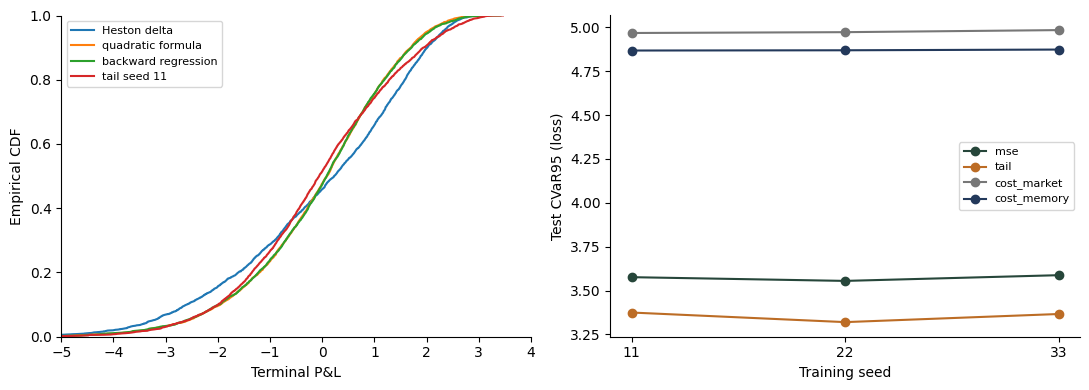

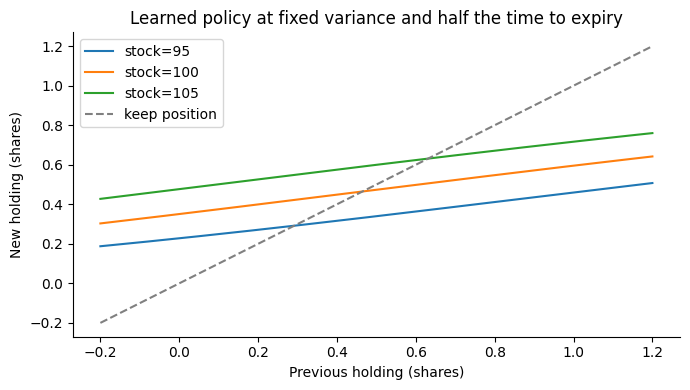

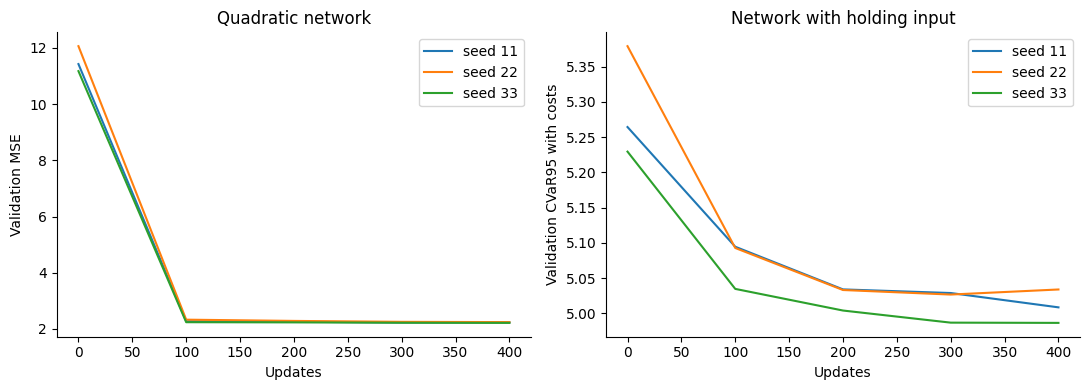

In [17]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
display = ["Heston delta", "quadratic formula", "backward regression", f"tail seed {reference_seed}"]
for name in display:
    x = np.sort(results[name]["pnl"])
    ax[0].plot(x, np.arange(1, len(x)+1)/len(x), label=name)
ax[0].set(xlabel="Terminal P&L", ylabel="Empirical CDF", xlim=(-5, 4), ylim=(0, 1))
ax[0].legend(fontsize=8)
for name, color in [("mse", "#26463a"), ("tail", "#bc6c25"),
                    ("cost_market", "#777777"), ("cost_memory", "#23395b")]:
    ys = [report["metrics"][f"{name} seed {seed}"]["cvar95"] for seed in CFG["seeds"]]
    ax[1].plot(CFG["seeds"], ys, "o-", label=name, color=color)
ax[1].set(xlabel="Training seed", ylabel="Test CVaR95 (loss)", xticks=CFG["seeds"])
ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "outcomes.png", dpi=160); plt.show()

previous = torch.linspace(-0.2, 1.2, 141)
fig, ax = plt.subplots(figsize=(7, 4))
for spot in [95., 100., 105.]:
    tau = MODEL.expiry/2
    x = torch.column_stack([torch.full_like(previous, tau/MODEL.expiry),
                            torch.full_like(previous, math.log(spot/MODEL.strike)/math.sqrt(MODEL.theta*tau)),
                            torch.zeros_like(previous), previous-0.5])
    with torch.no_grad():
        action = models[reference_seed]["cost_memory"](x).numpy()
    ax.plot(previous, action, label=f"stock={spot:g}")
ax.plot(previous, previous, "--", color="grey", label="keep position")
ax.set(xlabel="Previous holding (shares)", ylabel="New holding (shares)",
       title="Learned policy at fixed variance and half the time to expiry")
ax.legend(); fig.tight_layout(); fig.savefig(OUT / "holding_response.png", dpi=160); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for seed in CFG["seeds"]:
    for name, axis in [("mse", axes[0]), ("cost_memory", axes[1])]:
        history = fit_records[seed][name]["history"]
        axis.plot([h["step"] for h in history], [h["validation"] for h in history], label=f"seed {seed}")
axes[0].set(title="Quadratic network", xlabel="Updates", ylabel="Validation MSE")
axes[1].set(title="Network with holding input", xlabel="Updates", ylabel="Validation CVaR95 with costs")
for axis in axes: axis.legend()
fig.tight_layout(); fig.savefig(OUT / "learning.png", dpi=160); plt.show()

### Answer — the desk view (Plots 1–3, cost experiment)

**Plot 1 (P&L ECDFs).** The formula and the regression curves almost coincide. Heston delta has a visibly heavier left tail. The CVaR network differs from the formula mainly in the body of the distribution (more mass at lower P&L, less upside), while its small tail gain, about 2% of the CVaR, is not visible at this scale.

**Plot 2 (test CVaR by seed).** The four families keep their order for all three seeds. The cost networks hardly move with the seed, and the memory network is below the market-only network on every seed by about 0.1, well outside the seed spread. The CVaR network moves by about 0.05 across seeds, which is as large as its advantage over the formula.

**Cost experiment (test, 50 bp, reference seed).**

| policy | CVaR | RMSE | SD | mean paid cost |
|---|---|---|---|---|
| formula + costs | 5.612 | 2.385 | 1.656 | 1.657 |
| band | 4.962 | 1.929 | 1.604 | 1.005 |
| network, market state only | 4.969 | 2.161 | 1.760 | 1.178 |
| network with previous holding | 4.869 | 2.088 | 1.747 | 1.066 |

The band pays the least and has the lowest RMSE and SD; the memory network has the lowest CVaR (by 0.093, unresolved) while paying slightly more. A policy that pays less need not hedge better: the unhedged position pays nothing and has CVaR 13.6; and among the cost-aware policies the one that pays less (the band) is not the one with the lowest tail risk.

**Plot 3 (holding response at $\tau=T/2$, $v=\bar v$, reference seed).** Read off the plot: for each stock level the new holding is almost a straight line in the previous holding with slope about 0.24 (roughly 0.23–0.25), far below the 45° "keep position" line, and it crosses that line at about 0.3, 0.47 and 0.63 for $S=95,100,105$. A band would run along the 45° line (slope 1, no trade) over an interval and be flat outside it; there is no such segment. We see **partial adjustment**: roughly three quarters of the gap to a state-dependent target is closed at each date, and the target rises with the stock. This is a smooth contraction, not a learned no-trade zone. One state slice (one date, one variance level, one seed) cannot show how the policy behaves elsewhere, and the memory network's better CVaR than the market-only network shows that the holding input helps, not that a band was learned. The band does the same job with two parameters.

**Does the previous holding carry all the state for terminal CVaR?** No. It captures the immediate trading cost, which depends on the change from the holding already in place. Terminal CVaR is a non-linear function of the *total* P&L, so the right decision also depends on where the path stands relative to the tail: a path that has already lost much can take risk differently from one that has banked gains, and with costs the accumulated paid cost matters too. The state should include the accumulated net gains (`include_gain=True` in `HedgeNet`), or the threshold-augmented formulation of CVaR; we do not test this here and flag it as a limit (the optional extension).

**Learning curves** (third figure). The MSE networks (left) and the memory networks (right) settle within the first 200–300 updates; the three seeds start apart (validation CVaR roughly 5.2–5.4 at update 0, read from the plot) and the best checkpoints end within about 0.04 of each other (4.986–5.027).

## Brief 6 — Stress the hedges, find where they lose, decide

Every result so far trusts your model twice: in the formula's parameters and in the
simulator that produced the training paths. A calibration is not the market, and the
market can move after you calibrate.

**Task F1.** Implement `stress_test`. Simulate `n` paths from `scenario` with `seed`,
score every frozen policy on them with the supplied `frozen_pnl`, and return each
policy's CVaR and the paired CVaR interval for each declared pair (first minus second).
Do not refit, recalibrate or re-tune anything, and keep the premium.

In [18]:
def frozen_pnl(s, v):
    """Terminal P&L of the frozen reference-seed policies and benchmarks on paths (s, v)."""
    data = tensors(s, v, MODEL)
    _, quad = formula_policies(s, v)
    ref = CFG["seeds"][0]
    out = {"unhedged": account(np.zeros_like(quad), s), "quadratic formula": account(quad, s),
           f"tail seed {ref}": network_result(models[ref]["tail"], data),
           "band + costs": account(band_policy(quad, BAND_LOWER, BAND_UPPER), s, CFG["rate"]),
           f"cost_memory seed {ref}": network_result(models[ref]["cost_memory"], data, CFG["rate"])}
    return {name: result["pnl"] for name, result in out.items()}

def stress_test(scenario, n, seed, pairs):
    s, v = simulate(n, seed, scenario)                           # paths from the changed market
    pnls = frozen_pnl(s, v)                                      # frozen policies, desk-model features, same premium
    loss_cvar = lambda x: cvar_numpy(-x)                         # CVaR of the loss L = -X
    risk = {name: float(loss_cvar(p)) for name, p in pnls.items()}
    intervals = {f"{a} minus {b}": paired_interval(pnls[a], pnls[b], loss_cvar, repeats=CFG["bootstrap"])
                 for a, b in pairs}
    return risk, intervals

PAIRS = [(f"tail seed {reference_seed}", "quadratic formula"),
         (f"cost_memory seed {reference_seed}", "band + costs")]
risk_a, intervals_a = stress_test(MODEL, 400, 5, PAIRS)
risk_b, _ = stress_test(MODEL, 400, 5, PAIRS)
check_s, check_v = simulate(400, 5, MODEL)
assert risk_a == risk_b and set(intervals_a) == {f"{a} minus {b}" for a, b in PAIRS}
assert all(np.isclose(intervals_a[f"{a} minus {b}"]["estimate"], risk_a[a]-risk_a[b]) for a, b in PAIRS), \
    "Each interval should be for the difference in CVaR of the two policies."
assert np.isclose(risk_a["quadratic formula"], cvar_numpy(-frozen_pnl(check_s, check_v)["quadratic formula"]))
print("✓ F1: one seed, one set of paths; frozen policies scored on the scenario.")

SCENARIOS = {"desk model": MODEL,
             "vol of vol +30%": replace(MODEL, xi=1.3*MODEL.xi),
             "correlation weaker by 40%": replace(MODEL, rho=0.6*MODEL.rho),
             "long-run variance +40%": replace(MODEL, theta=1.4*MODEL.theta)}
stress = {}
for label, scenario in SCENARIOS.items():
    risk, intervals = stress_test(scenario, CFG["stress"], CFG["stress_seed"], PAIRS)
    stress[label] = dict(risk=risk, intervals=intervals)
    print(f"{label:28s}" + "  ".join(f"{k} {v:.3f}" for k, v in risk.items()))
    for key, d in intervals.items():
        print(f"{'':28s}{key}: {d['estimate']:+.3f} [{d['ci95'][0]:+.3f}, {d['ci95'][1]:+.3f}]")
(OUT / "stress.json").write_text(json.dumps(stress, indent=2))

✓ F1: one seed, one set of paths; frozen policies scored on the scenario.
desk model                  unhedged 14.388  quadratic formula 3.437  tail seed 11 3.338  band + costs 4.869  cost_memory seed 11 4.831
                            tail seed 11 minus quadratic formula: -0.099 [-0.151, -0.050]
                            cost_memory seed 11 minus band + costs: -0.039 [-0.144, +0.075]
vol of vol +30%             unhedged 14.085  quadratic formula 4.088  tail seed 11 4.016  band + costs 5.510  cost_memory seed 11 5.517
                            tail seed 11 minus quadratic formula: -0.071 [-0.124, -0.021]
                            cost_memory seed 11 minus band + costs: +0.007 [-0.111, +0.138]
correlation weaker by 40%   unhedged 17.628  quadratic formula 4.007  tail seed 11 3.982  band + costs 5.445  cost_memory seed 11 5.553
                            tail seed 11 minus quadratic formula: -0.025 [-0.087, +0.036]
                            cost_memory seed 11 minus band + cos

2963

### Answer — F1 (stress)

CVaR of the loss for the frozen policies on 4,000 freshly simulated paths per scenario (one seed for every scenario, so the scenarios share their random draws; these are not the market's test paths, so the desk-model row differs from the test table). In brackets: the change from the desk-model row.

| scenario | unhedged | quadratic formula | CVaR network | band + costs | memory network |
|---|---|---|---|---|---|
| desk model | 14.388 | 3.437 | 3.338 | 4.869 | 4.831 |
| vol of vol +30% | 14.085 (−0.303) | 4.088 (+0.651) | 4.016 (+0.678) | 5.510 (+0.641) | 5.517 (+0.686) |
| correlation weaker by 40% | 17.628 (+3.240) | 4.007 (+0.570) | 3.982 (+0.644) | 5.445 (+0.576) | 5.553 (+0.722) |
| long-run variance +40% | 15.077 (+0.689) | 3.569 (+0.132) | 3.459 (+0.121) | 5.016 (+0.147) | 4.965 (+0.134) |

Paired differences within each scenario (first minus second, 95% interval):

| scenario | CVaR network − formula | memory network − band |
|---|---|---|
| desk model | −0.099 [−0.151, −0.050] | −0.039 [−0.144, +0.075] |
| vol of vol +30% | −0.071 [−0.124, −0.021] | +0.007 [−0.111, +0.138] |
| correlation weaker by 40% | −0.025 [−0.087, +0.036] | +0.108 [−0.012, +0.240] |
| long-run variance +40% | −0.110 [−0.163, −0.062] | −0.051 [−0.156, +0.062] |

**Which conclusions survive every scenario?** (i) Every hedge is far better than no hedge: unhedged CVaR is 14.1–17.6 against at most 5.6 for the hedged policies. (ii) The CVaR network stays below the formula in all four scenarios, but by a small margin, and with weaker correlation its interval contains zero. (iii) The memory network's edge over the band does **not** survive: the sign changes (negative, positive, positive, negative) and all four intervals contain zero.

**Which hedge degrades most, and why.** Vol-of-vol $+30\%$ and weaker correlation raise the CVaR of every hedged policy by 0.57–0.72 (17–20% for the frictionless policies, 12–15% with costs); long-run variance $+40\%$ raises it by only 0.12–0.15 (3–4%). The formula conditions on today's variance and the horizon (0.25 years) is only about a third of the mean-reversion time $1/\kappa\approx0.73$ years, so a wrong long-run level has limited effect, whereas $\xi$ and $\rho$ set the size of the vega exposure ($\propto\xi\sqrt{1-\rho^2}$) and of the correction $\rho\xi C_v/S$. Differences between hedges are small (at most about 0.15 in CVaR units, and degradations carry no intervals). The largest single degradation is the memory network's when correlation weakens (+0.722 against +0.576 for the band and +0.570 for the formula), the one scenario where its edge over the band flips (+0.108 [−0.012, +0.240]).

**Why a network inherits the simulator's errors and a formula does not.** A formula with slightly wrong parameters is still a smooth hedge with the right structure, and its error moves gradually with the parameter error. The network has absorbed the whole *joint law of the training paths* (the Euler scheme, the desk's $\kappa,\bar v,\xi,\rho$, the states it saw) into its weights; where the market's states or dynamics differ it extrapolates with nothing to constrain it, and no single parameter can be corrected. Its error is parameter error plus distribution error, and CVaR training, which fits a few tail paths per batch, can amplify it.

**Is a scenario a probability statement?** No. A scenario is a what-if chosen in advance; it carries no probability, the three scenarios are neither exhaustive nor equally plausible, and the table says nothing about how likely any of them is.

**Task F2.** Find where the losses come from. Given a P&L array and a group label for
every path, return for each group its share of all paths, its share of the worst
`round(tail * n)` paths, and its mean P&L. A group that holds far more of the tail than
of the paths is where the hedge loses.

In [19]:
def tail_share(pnl, groups, tail=0.05):
    pnl, groups = np.asarray(pnl, dtype=float), np.asarray(groups)
    assert pnl.shape == groups.shape
    m = int(round(tail * len(pnl)))
    if m < 1:
        raise ValueError("tail * number of paths rounds to zero paths")
    worst = np.argsort(pnl, kind="stable")[:m]                   # the m smallest P&Ls = the m largest losses
    in_tail = np.zeros(len(pnl), dtype=bool)
    in_tail[worst] = True
    out = {}
    for g in np.unique(groups):
        mask = groups == g
        out[str(g)] = dict(share=float(mask.mean()),
                           tail_share=float(in_tail[mask].sum() / m),     # fraction of the worst m paths lying in group g
                           mean=float(pnl[mask].mean()))
    return out

toy = tail_share(np.array([-5., -4., 1., 2., 3., 0., -1., 4., 5., 6.]), np.array(list("aaabbbbbbb")), tail=0.2)
assert np.isclose(toy["a"]["share"], 0.3) and np.isclose(toy["a"]["mean"], -8/3)
assert np.isclose(toy["a"]["tail_share"], 1.0) and np.isclose(toy["b"]["tail_share"], 0.0), \
    "tail_share is the group's share of the worst paths, not the chance that a group member is among them."
print("✓ F2: shares of paths and of the tail by group.")

realised = np.sqrt((np.diff(np.log(test_s), axis=1)**2).sum(1)/MODEL.expiry)
last_month = MODEL.steps - 21
crossed = (np.sign(test_s[:, last_month:]-MODEL.strike) != np.sign(test_s[:, last_month:last_month+1]-MODEL.strike)).any(1)
groups = np.char.add(np.where(realised > np.median(realised), "high vol, ", "low vol, "),
                     np.where(crossed, "crossed K in last month", "no late crossing"))
diagnosis = {}
for name in ["quadratic formula", f"tail seed {reference_seed}", "band + costs", f"cost_memory seed {reference_seed}"]:
    diagnosis[name] = tail_share(results[name]["pnl"], groups)
    print(name)
    for g, row in diagnosis[name].items():
        print(f"   {g:36s} paths {row['share']:.2f}   worst 5% {row['tail_share']:.2f}   mean P&L {row['mean']:+.3f}")
(OUT / "diagnosis.json").write_text(json.dumps(diagnosis, indent=2))

✓ F2: shares of paths and of the tail by group.
quadratic formula
   high vol, crossed K in last month    paths 0.16   worst 5% 0.45   mean P&L -1.256
   high vol, no late crossing           paths 0.34   worst 5% 0.56   mean P&L -0.832
   low vol, crossed K in last month     paths 0.09   worst 5% 0.00   mean P&L +1.154
   low vol, no late crossing            paths 0.41   worst 5% 0.00   mean P&L +0.780
tail seed 11
   high vol, crossed K in last month    paths 0.16   worst 5% 0.35   mean P&L -0.801
   high vol, no late crossing           paths 0.34   worst 5% 0.65   mean P&L -1.008
   low vol, crossed K in last month     paths 0.09   worst 5% 0.00   mean P&L +1.726
   low vol, no late crossing            paths 0.41   worst 5% 0.00   mean P&L +0.593
band + costs
   high vol, crossed K in last month    paths 0.16   worst 5% 0.47   mean P&L -2.421
   high vol, no late crossing           paths 0.34   worst 5% 0.54   mean P&L -1.814
   low vol, crossed K in last month     paths 0.09   worst

2164

### Answer — F2 (where the hedges lose)

Test paths are grouped by realised volatility (above or below the median) and by whether the stock crossed the strike in the last month; the shares of all paths are 16% (high vol, crossed), 34% (high vol, no late crossing), 9% and 41% (the two low-vol groups).

| policy | group (share of paths) | share of worst 5% | mean P&L |
|---|---|---|---|
| quadratic formula | high vol, crossed K in last month (16%) | 45% | −1.256 |
|  | high vol, no late crossing (34%) | 56% | −0.832 |
|  | low vol, crossed K in last month (9%) | 0% | +1.154 |
|  | low vol, no late crossing (41%) | 0% | +0.780 |
| CVaR network | high vol, crossed K in last month (16%) | 35% | −0.801 |
|  | high vol, no late crossing (34%) | 65% | −1.008 |
|  | low vol, crossed K in last month (9%) | 0% | +1.726 |
|  | low vol, no late crossing (41%) | 0% | +0.593 |
| band + costs | high vol, crossed K in last month (16%) | 47% | −2.421 |
|  | high vol, no late crossing (34%) | 54% | −1.814 |
|  | low vol, crossed K in last month (9%) | 0% | +0.025 |
|  | low vol, no late crossing (41%) | 0% | −0.171 |
| memory network | high vol, crossed K in last month (16%) | 32% | −1.866 |
|  | high vol, no late crossing (34%) | 64% | −2.150 |
|  | low vol, crossed K in last month (9%) | 0% | +0.870 |
|  | low vol, no late crossing (41%) | 4% | −0.474 |

**Where the worst outcomes come from.** For the formula all of the worst 5% lies in the high-volatility half. Late crossers hold 45% of the tail with 16% of the paths (2.8 times their share); high-vol non-crossers hold 56% with 34% (1.6 times); low-vol paths hold none. The band has the same pattern (47% and 54%); relative to the frictionless formula its mean P&L is lower by roughly 1 in every group (−1.16, −0.98, −1.13, −0.95; the average cost paid is 1.005), a little more for late crossers. The CVaR network and the memory network move tail mass from the late crossers (35% and 32%) to the high-vol non-crossers (65% and 64%); the memory network also puts 4% of its tail on calm paths, where costs alone push the P&L down.

**Gamma.** A call has gamma $\Gamma=\partial^2C/\partial S^2\approx\varphi(d_1)/(S\sigma\sqrt\tau)$, largest at the money and exploding as $\tau\to0$; the seller is short that gamma: the delta swings from about 0 to about 1 over a tiny range of stock prices. Rebalanced once a day the hedge is always one step stale; the per-step error is about $\tfrac12\Gamma S^2\sigma^2(\Delta W^2-\Delta t)$, with variance $\tfrac12(\Gamma S^2\sigma^2\Delta t)^2\propto1/\tau$ at the strike. A move toward the strike late in the option's life therefore hurts a short call most: the delta flips while the stock oscillates around $K$ (pin risk), and high realised volatility makes every $\Delta W^2$ large. That is the pattern in the table: late crossers carry 2.8 times their share of the tail.

The table does not prove this. The largest absolute part of the tail (56% for the formula) is in high-vol paths that did *not* cross late, where the loss may come from vega ($dW^\perp$) risk, which also grows with realised volatility, or from gamma earlier in the option's life; and the groups are defined from the whole path afterwards, so they say where losses are, not what causes them.

**Does the CVaR network's difference fit?** It fits, without being proven. Against the formula it lowers the late-crossing groups' tail share (45% to 35%) and improves their mean P&L (high vol −1.256 to −0.801; low vol +1.154 to +1.726), which is where gamma is concentrated, and it pays in the groups that did not cross (−0.832 to −1.008 and +0.780 to +0.593), so tail mass moves to the high-vol non-crossers (56% to 65%). That is what a policy handling the near-strike, near-expiry region more carefully, at the expense of the body, would produce. It is also what a policy with a higher standard deviation (1.517 against 1.422) produces by reshuffling which paths fall in the tail. Four groups, 200 tail paths, one test set and one seed cannot separate the two.

**What we would run next (declared, not run here).** (a) Compare the network's and the formula's holdings directly in late-life, near-strike states. (b) Refine the rebalancing grid on desk-model paths, with no test paths, to separate time-discretisation error from incomplete-market risk. (c) Repeat the diagnosis for the other seeds.

## Your decision

Submit on Canvas by Wednesday 25 November 2026, in pairs: the completed notebook,
hedge_desk_output as a zip file, and a desk memo as one PDF of at most five pages.
See the handout for the rubric and required explanations.

1. Which hedge would you deploy without costs under a quadratic mandate? Under a tail mandate?
2. What changes when costs arrive? Is the network's extra complexity justified?
3. Which comparisons are distinguishable from sampling error for the declared seed?
   Does the conclusion survive the other training seeds, the market's own paths and the stresses?
4. Where does each hedge lose, and does the CVaR network's difference from the formula make sense there?
5. Identify approximation, optimisation, sampling, calibration and model error.
6. Why have you neither a replication guarantee nor a global Heston optimality certificate?

Optional further work: add accumulated net gains to the CVaR state; refit the networks
under a stressed model and compare; use price history when variance becomes unobservable;
or use an Asian claim and add its running average. Declare each new experiment first.

Background: Lecture Notes §3 (Theorem 3.9 and Remark 3.11), §4.5 and §8.5;
Lectures 5–7. See [Buehler et al., Deep Hedging](https://arxiv.org/abs/1802.03042)
and [Rockafellar–Uryasev, general loss distributions](https://doi.org/10.1016/S0378-4266(02)00271-6).

### Answer — Your decision

**1. Frictionless hedge.** *Quadratic mandate: the quadratic formula* $h_{\rm quad}=C_S+\rho\xi C_v/S$. It has the lowest test RMSE (1.423); the regression is worse by +0.049 in MSE ([+0.024, +0.072]) and the MSE network by a similar amount (+0.052 against the regression; 1.454–1.458 RMSE), so nothing learned beats it, and it needs no training. *Tail mandate: the CVaR network, as a modest upgrade of the formula.* Its test CVaR is lower by 0.059 (interval [−0.107, −0.009]) and lower on all three seeds (−0.06, −0.11, −0.07), at the price of a higher standard deviation (1.517 against 1.422). The gain is about 2% of the formula's CVaR (−0.06, −0.11, −0.07 across seeds), of the same order as the network's seed spread (3.320–3.374), and unresolved when correlation weakens (−0.025 [−0.087, +0.036]); the formula is the safe fallback.

**2. With 50 bp costs: the formula inside a no-trade band** ($a=0.04$, $b=0.08$). Costs change the problem: the formula pays 1.657 per path (46% of the premium) and its CVaR rises from 3.434 to 5.612. The band cuts CVaR by 0.650 (interval [−0.786, −0.514]) and costs by 39%, with the lowest RMSE and SD of the cost-aware policies. The memory network is a further 0.093 lower in CVaR (interval [−0.195, +0.008], unresolved; lower on all seeds) with higher RMSE and SD, and loses the edge when correlation weakens (+0.108 [−0.012, +0.240]). It beats the market-only network clearly (−0.100, [−0.132, −0.069]), so memory matters inside the network family, but a two-parameter band does almost the same job. The extra complexity is not justified.

**3. What is distinguishable, and does it survive?** For the declared seed five of the six intervals exclude zero; the exception is memory network against band. Across the other two seeds the signs of the CVaR-network, memory-versus-band and memory-versus-market differences are unchanged, but the CVaR-network gain is as large as the seed spread. The market's own paths shrink the CVaR network's edge relative to fresh desk-model paths (−0.059 against −0.099 [−0.151, −0.050] in the stress table; the intervals overlap), as we would expect if part of the edge is specific to the desk's simulator. Under stress the CVaR network remains below the formula in all four scenarios, with zero inside the interval for weaker correlation, while the memory-versus-band sign flips twice. Scenarios are not probabilities.

**4. Where each hedge loses.** In high-realised-volatility paths, above all those that cross the strike in the last month (2.8 times their share of the formula's tail), consistent with gamma; the largest absolute share is in high-vol paths without a late crossing, where vega risk dominates. The CVaR network's difference (less tail share and a better mean for late crossers, worse for the rest) is consistent with this, not proof of it.

### Answer — five errors, certificate versus benchmark, and the pricing question

**5. Five errors, one example each.**

- *Approximation:* the regression's finite basis (three hedge features, five nuisance features) and the restricted 2×32 network family cannot represent the exact conditional ratio; the regression ends at RMSE 1.440 against 1.423 for the formula (MSE gap +0.049, [+0.024, +0.072]). Using the continuous-time formula in a 63-date Euler market is another approximation.
- *Optimisation:* the MSE networks stop at RMSE 1.454–1.458 after 400 noisy steps against 1.423 for the formula; CVaR training uses a biased batch-profiled gradient, and the three seeds end at CVaR 3.320–3.374.
- *Sampling:* the test CVaR rests on 200 tail paths of 4,000; the interval for memory network against band, [−0.195, +0.008], cannot decide the comparison.
- *Calibration:* the fit misses the quotes by 0.32 vol points, one half-spread, and $\kappa,\bar v$ are poorly identified (the smile-only fit hits the $\kappa$ bound); the premium carries the same quote noise.
- *Model:* the market is not the calibrated Heston, and stock-and-cash hedging cannot remove volatility risk. Stress shows the cost: vol-of-vol $+30\%$ or weaker correlation raises the formula's CVaR by 19% and 17%.

**Exact certificate versus benchmarks.** The finite tree is the only exact certificate: all conditional expectations are computed, the node regressions equal the global weighted projection to $10^{-10}$ and the residual is exactly orthogonal. In Heston there is no such object: states are continuous with one observation each, so we have estimated coefficients, a continuous-time formula that is only a benchmark for the Euler problem, networks from a non-convex training run, and sampling evidence from 4,000 test paths and three seeds.

**6. No replication guarantee and no global optimality certificate.** *Replication:* volatility cannot be traded, so unless $\lvert\rho\rvert=1$ part of the call's risk ($dW^\perp$) is unhedgeable, and trading is discrete and costly; the premium is not a replication cost and residual risk remains (SD about 1.422 on a premium of 3.613). *Optimality:* the discrete Euler problem has no closed-form solution; the formula is a continuous-time benchmark; regression and networks are restricted families trained on finite samples with a non-convex objective; CVaR is not a one-step conditional quantity (the state would need accumulated gains); and the market differs from the desk's model.

**Pricing question.** The scores are risk levels at the *quoted* premium $c_0$, for frozen, restricted policies. A risk-indifference price is the premium $p^*$ at which the *optimal* risk with the claim equals the optimal risk without it, $\inf_\phi\rho(p^*-H+G_\phi)=\inf_\phi\rho(G_\phi)$ (the no-claim baseline of §8.5). Our scores supply neither the infimum over all admissible hedges (each restricted policy gives an upper bound on the risk) nor the baseline, and the quote is not the premium that equalises them. Cash invariance also shifts every score one-for-one with $c_0$, so ranking hedges at a fixed premium says nothing about the level of the price. With CVaR the baseline is 0 (hold nothing), and each score gives only a one-sided bound, $p^*\le c_0+\text{score}$ (up to sampling and model error): 7.05 for the formula and 6.93 for the best CVaR network, against a quote of 3.613. The other side is $p^*\ge\mathbb E^{\mathbb Q}[H]$ (CVaR is at least the mean loss), about 3.7 on the test paths. The bracket is wide, so these scores do not locate the indifference price.